In [23]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm
from models import hgm

In [1]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

NameError: name 'read_utils' is not defined

In [25]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

class PrepData(NamedTuple):
	N_mean: tuple[float, ...]
	N_std: tuple[float, ...]
	B_hl_mean: tuple[float, ...] | None = None
	B_hl_std: tuple[float, ...] | None = None

In [26]:
def train_joint_model(model, splits, N, B_ll, B_hl, hyperparameters=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 2000,
			'max_patience': 2000 * 0.25,
			'learning_rate': 1E-4, #1E-4, #0.005, # 0.02
			'w1_reg_lambda': 0, #0.002,
			'w2_reg_lambda': 0, #0.5, #0.01,
			'ccadiag_lambda': 0.6,
			'ccaunit_lambda': 1 - 0.6,
			'loss1_lambda': 0.5,
			'loss2_lambda': 1. - 0.5,
			'dimensions': 2
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss1_lambda'], hyperparameters['loss2_lambda']),
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']),
		cca_lambdas=(hyperparameters['ccadiag_lambda'], hyperparameters['ccaunit_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =============================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mpe_losses_per_split = list()
	mpe_losses_tr_per_split = list()
	__grads_per_split = list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_train, N_eval = jnp.array(N[train]), jnp.array(N[eval])
		B_hl_train, B_hl_eval = jnp.array(B_hl[train]), jnp.array(B_hl[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_eval = PrepData(
			N_mean=tuple((map(float, N_eval.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		params = model.init_params(seeds,
								   (n_neurons, n_dimensions),
								   (n_behaviors_hl, n_dimensions),
								   (n_behaviors_ll, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else ())

		# optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(
		# 	init_value=learning_rate,
		# 	decay_steps=max_epochs,
		# 	alpha=1E-2
		# ))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		losses = [model.loss_fn(params, N_eval, B_ll_eval, B_hl_eval, lambdas, prep_data_eval).item()]
		losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()]
		mpe_losses = [model.mpe_loss_fn(params, N_eval, B_ll_eval, prep_data_eval).item()]
		mpe_losses_tr = [model.mpe_loss_fn(params, N_train, B_ll_train, prep_data_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mpe_loss = sys.float_info.max
		best_mpe_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train)

			loss = model.loss_fn(params, N_eval, B_ll_eval, B_hl_eval, lambdas, prep_data_eval).item()
			loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()
			mpe_loss = model.mpe_loss_fn(params, N_eval, B_ll_eval, prep_data_eval).item()
			mpe_loss_tr = model.mpe_loss_fn(params, N_train, B_ll_train, prep_data_train).item()
			__grads.append(__grad)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					best_loss = loss
					best_loss_tr = loss_tr
					best_mpe_loss = mpe_loss
					best_mpe_loss_tr = mpe_loss_tr
				else:
					patience += 1
					if patience > max_patience:
						params = best_params
						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]
						mpe_losses_tr = mpe_losses_tr + [best_mpe_loss_tr for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses.append(loss)
			losses_tr.append(loss_tr)
			mpe_losses.append(mpe_loss)
			mpe_losses_tr.append(mpe_loss_tr)

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mpe_losses_per_split.append(mpe_losses)
		mpe_losses_tr_per_split.append(mpe_losses_tr)
		__grads_per_split.append(__grads)

		print(f'Split {s_id} completed. ', end='')

		# predicting and scoring ========================================================================
		score_per_neuron = model.score_fn(params, N_eval, B_ll_eval, prep_data_eval)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# ===========================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mpe_losses_per_split), np.array(mpe_losses_tr_per_split), __grads_per_split

In [27]:
def train_joint_models(model, filenames, discrete_states, eigenworms, traces):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mpe_losses = list()
	models_mpe_losses_tr = list()
	dataset_spits = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]} ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mpe_losses_per_split, mpe_losses_tr_per_split,
		 __grads_per_split) = train_joint_model(model, splits,
												jnp.array(traces[i].values),
												jnp.array(eigenworms[i].values),
												jnp.array(discrete_states[i].values))

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mpe_losses.append(mpe_losses_per_split)
		models_mpe_losses_tr.append(mpe_losses_tr_per_split)
		dataset_spits.append(splits)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mpe_losses, models_mpe_losses_tr, dataset_spits, __models_grads

In [28]:
read_ids = (24, 24)
read_ids_gfp = (3, 3)
plot_id = 24 - read_ids[0]  # 33

# dims = 2
dims_generation = 2
weights = (0.5, 2.)

# selection_n = ['AVAR', 'AVEL', 'BAGR', 'BAGL', 'URYVR', 'URYVL']  # high m portion for worm ??
# selection_n = ['DB01', 'VB02', 'RMDDR', 'RMDDL', 'SMDDR', 'SMDVR']  # high c portion for worm 33
# selection_n = ['VB02', 'SMDDR', 'SMDDL', 'RMDDR', 'RMDDL', 'SMDVR']  # high c portion for worm 24
selection_n = ['AVAR', 'VB02', 'SMDDR']
# selection_bhl = ['REV']  # ['REV', 'VENTRAL_TURN']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'FWD', 'PAUSE', 'TRACKING_FAILURE']

In [29]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path, slice=(read_ids[0], read_ids[1] + 1))

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

discrete_states = [ds[selection_bhl] for ds in discrete_states]
# traces = [t[selection_n] for t in traces]



artificial = False
if artificial:
	filenames_art = list()
	discrete_states_art = discrete_states.copy()
	eigenworms_art = eigenworms.copy()
	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()
	for i in range(len(filenames)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames[i],
														 traces[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)


	traces = traces_art

In [30]:
(clm_models_params,
 clm_models_scores,
 clm_models_losses, clm_models_losses_tr,
 clm_models_mpe_losses, clm_models_mpe_losses_tr,
 splits,
 __clm_models_grads) = train_joint_models(clm,
												filenames,
												discrete_states,
												eigenworms,
												traces)


1/1: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1327 epochs: Split 3 completed. Stopped after 1255 epochs: Split 4 completed. 

In [31]:
(hgm_models_params,
 hgm_models_scores,
 hgm_models_losses, hgm_models_losses_tr,
 hgm_models_mpe_losses, hgm_models_mpe_losses_tr,
 splits,
 __hgm_models_grads) = train_joint_models(hgm,
												filenames,
												discrete_states,
												eigenworms,
												traces)


1/1: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 1436 epochs: Split 3 completed. Stopped after 1242 epochs: Split 4 completed. 

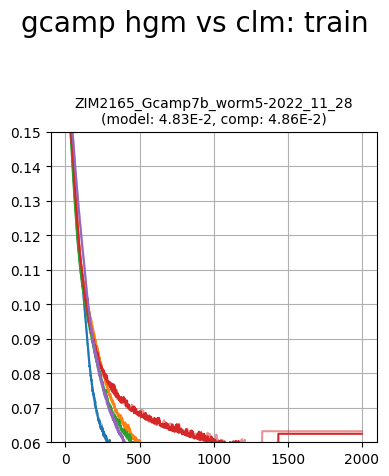

In [32]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: train',
							  filenames,
							  hgm_models_losses_tr, clm_models_losses_tr,
							  plots_per_row=1, ylimits=(0.06, 0.15))

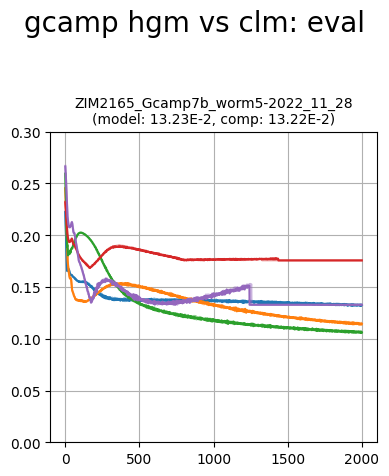

In [33]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: eval',
							  filenames,
							  hgm_models_losses, clm_models_losses,
							  plots_per_row=1, ylimits=(0.0, 0.3))

# performance

In [34]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [35]:
neuron_scores = assemble(filenames, traces, clm_models_scores, hgm_models_scores)

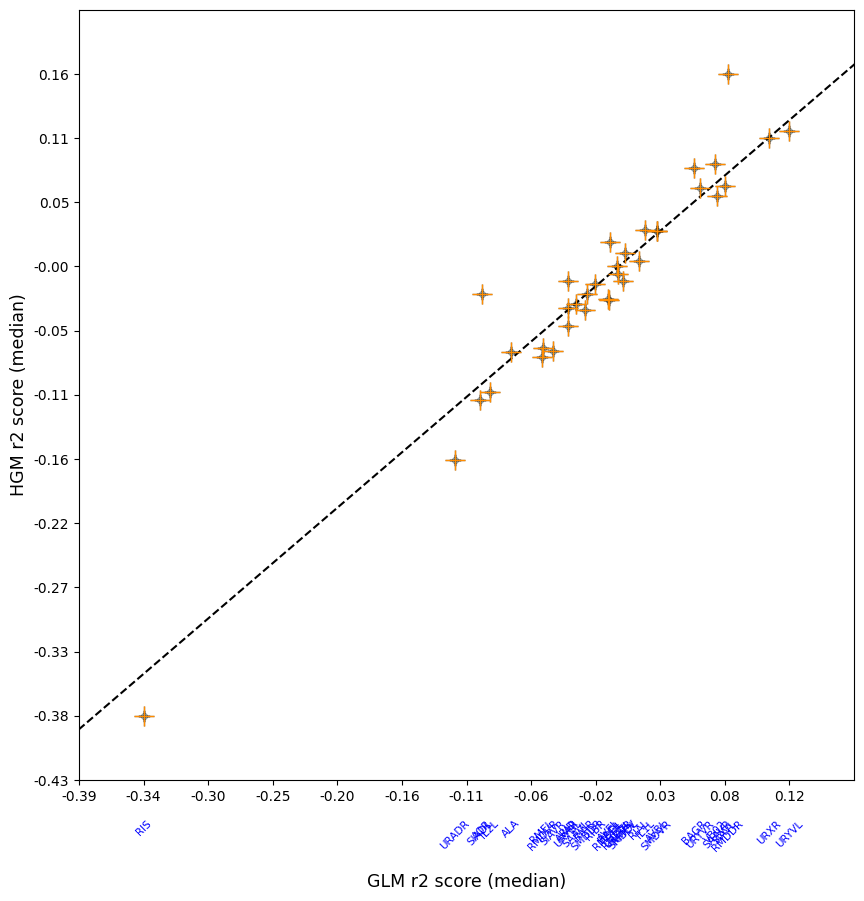

In [36]:
plot_utils.plot_performance_plot(neuron_scores, None,
								 limits=None, content_size=20)

In [37]:
# plot_utils.plot_improvement_plot(neuron_scores, None,
# 								 limits=None, content_size=20)

# traces

In [38]:
def predict_wrapper(model, N, B_ll, params, neurons_labels):
	N_res_pred, N_res, N_rec = model.obtain(params,
											N, B_ll,
											PrepData(
												N_mean=tuple((map(float, N.mean(axis=0)))),
												N_std=tuple((map(float, jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std)))),
											))
	return tuple(pd.DataFrame(data=traces, columns=neurons_labels) for traces in (N_res_pred, N_res, N_rec))

In [39]:
clm_pres_res_rec = [[
	predict_wrapper(clm, jnp.array(traces[i].iloc[split[1]]), jnp.array(eigenworms[i].iloc[split[1]]), params, traces[i].iloc[split[1]].columns) for split, params in zip(splits[i], clm_models_params[i])
] for i in range(len(traces))]


hgm_pres_res_rec = [[
	predict_wrapper(hgm, jnp.array(traces[i].iloc[split[1]]), jnp.array(eigenworms[i].iloc[split[1]]), params, traces[i].iloc[split[1]].columns) for split, params in zip(splits[i], hgm_models_params[i])
] for i in range(len(traces))]



traces_splits = [[
	pd.DataFrame(data=traces[i].iloc[split[1]].values, columns=traces[i].iloc[split[1]].columns) for split in splits[i]
] for i in range(len(traces))]

discrete_states_splits = [[
	discrete_states[i].iloc[split[1]] for split in splits[i]
] for i in range(len(traces))]

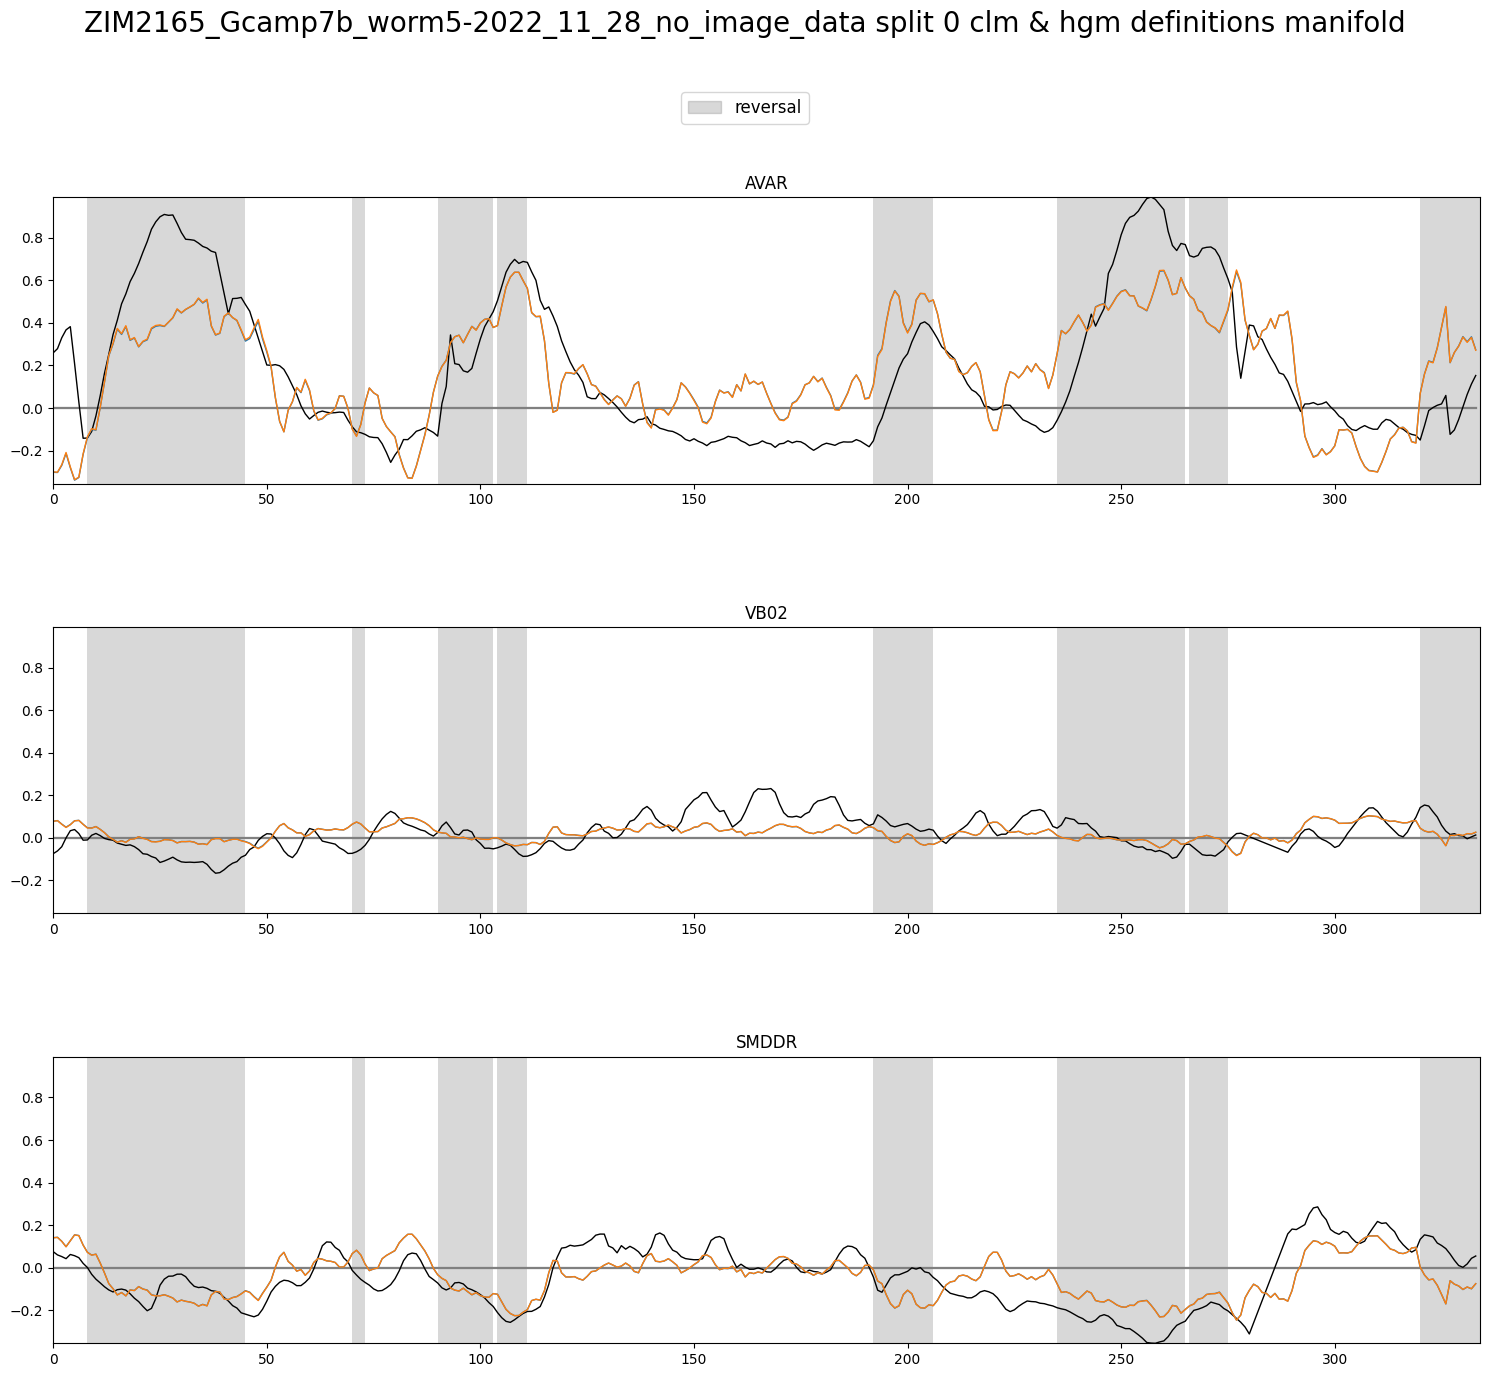

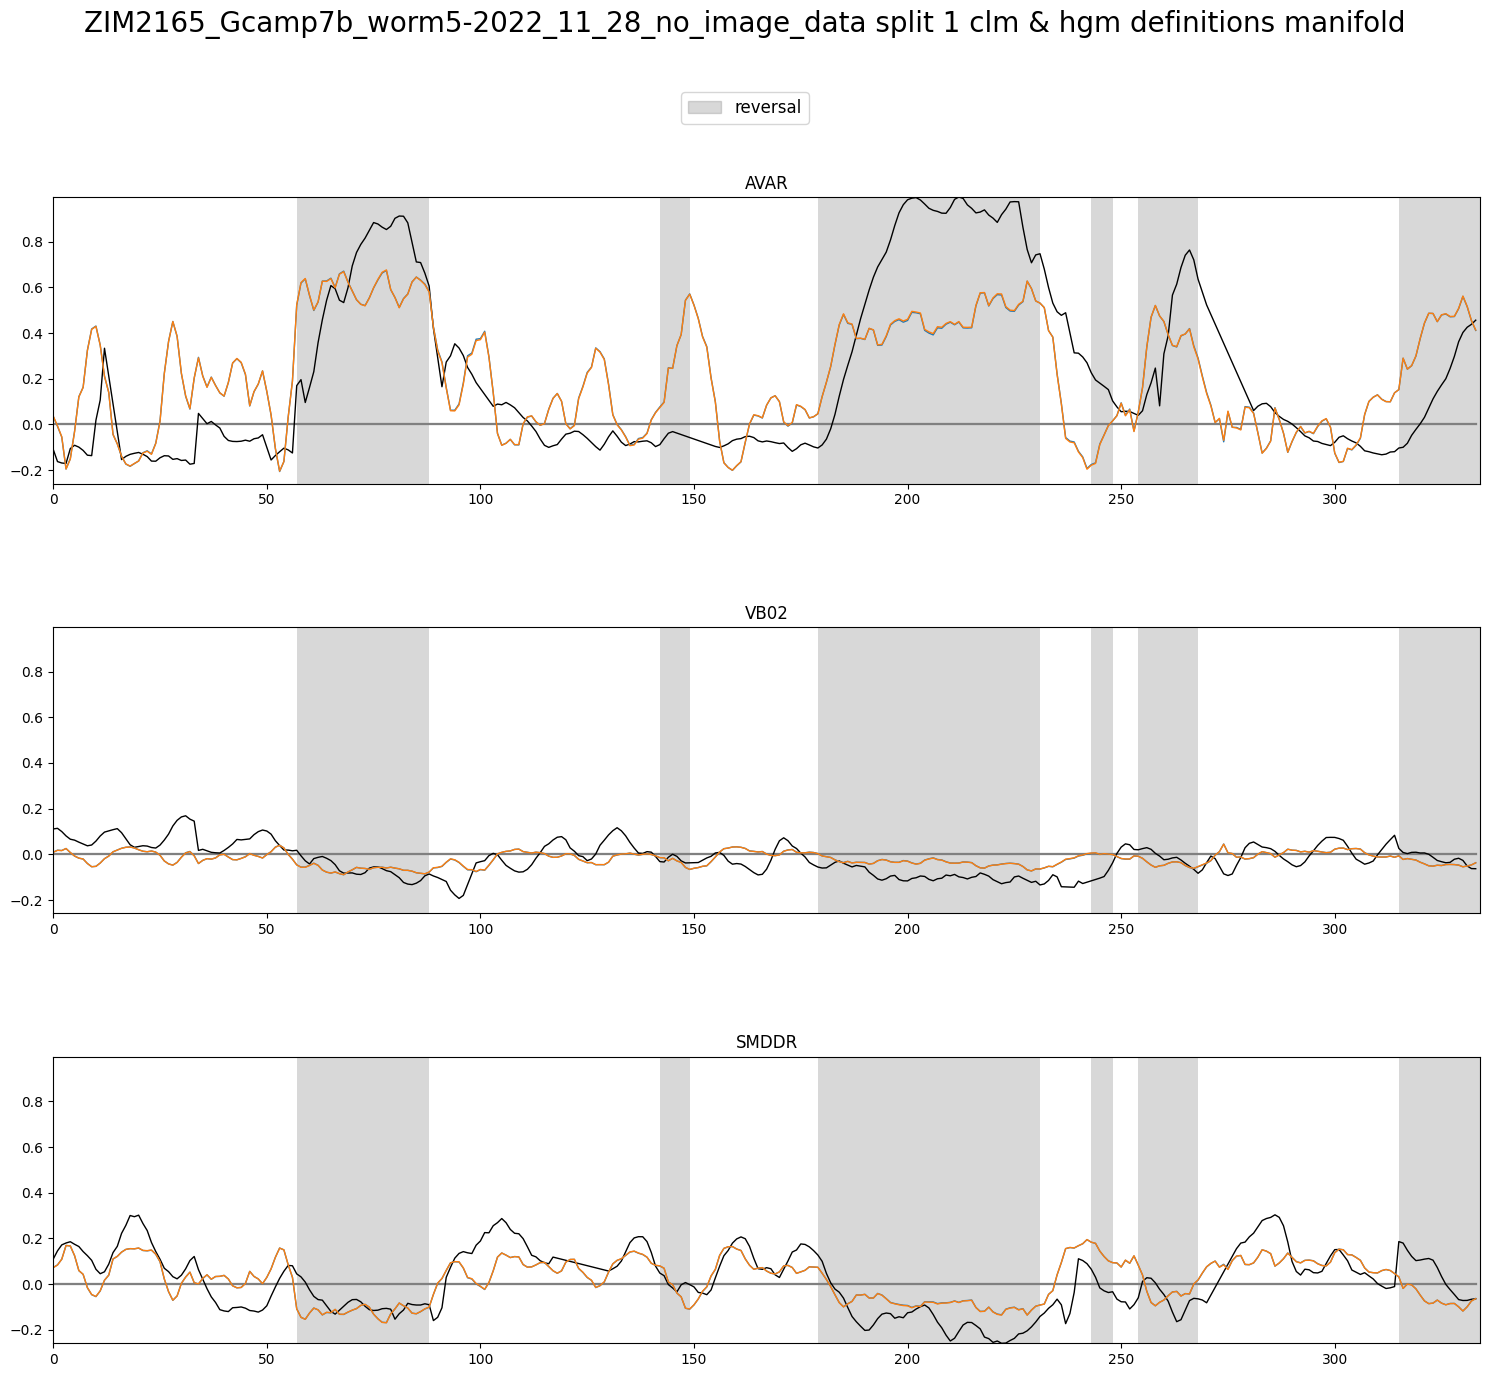

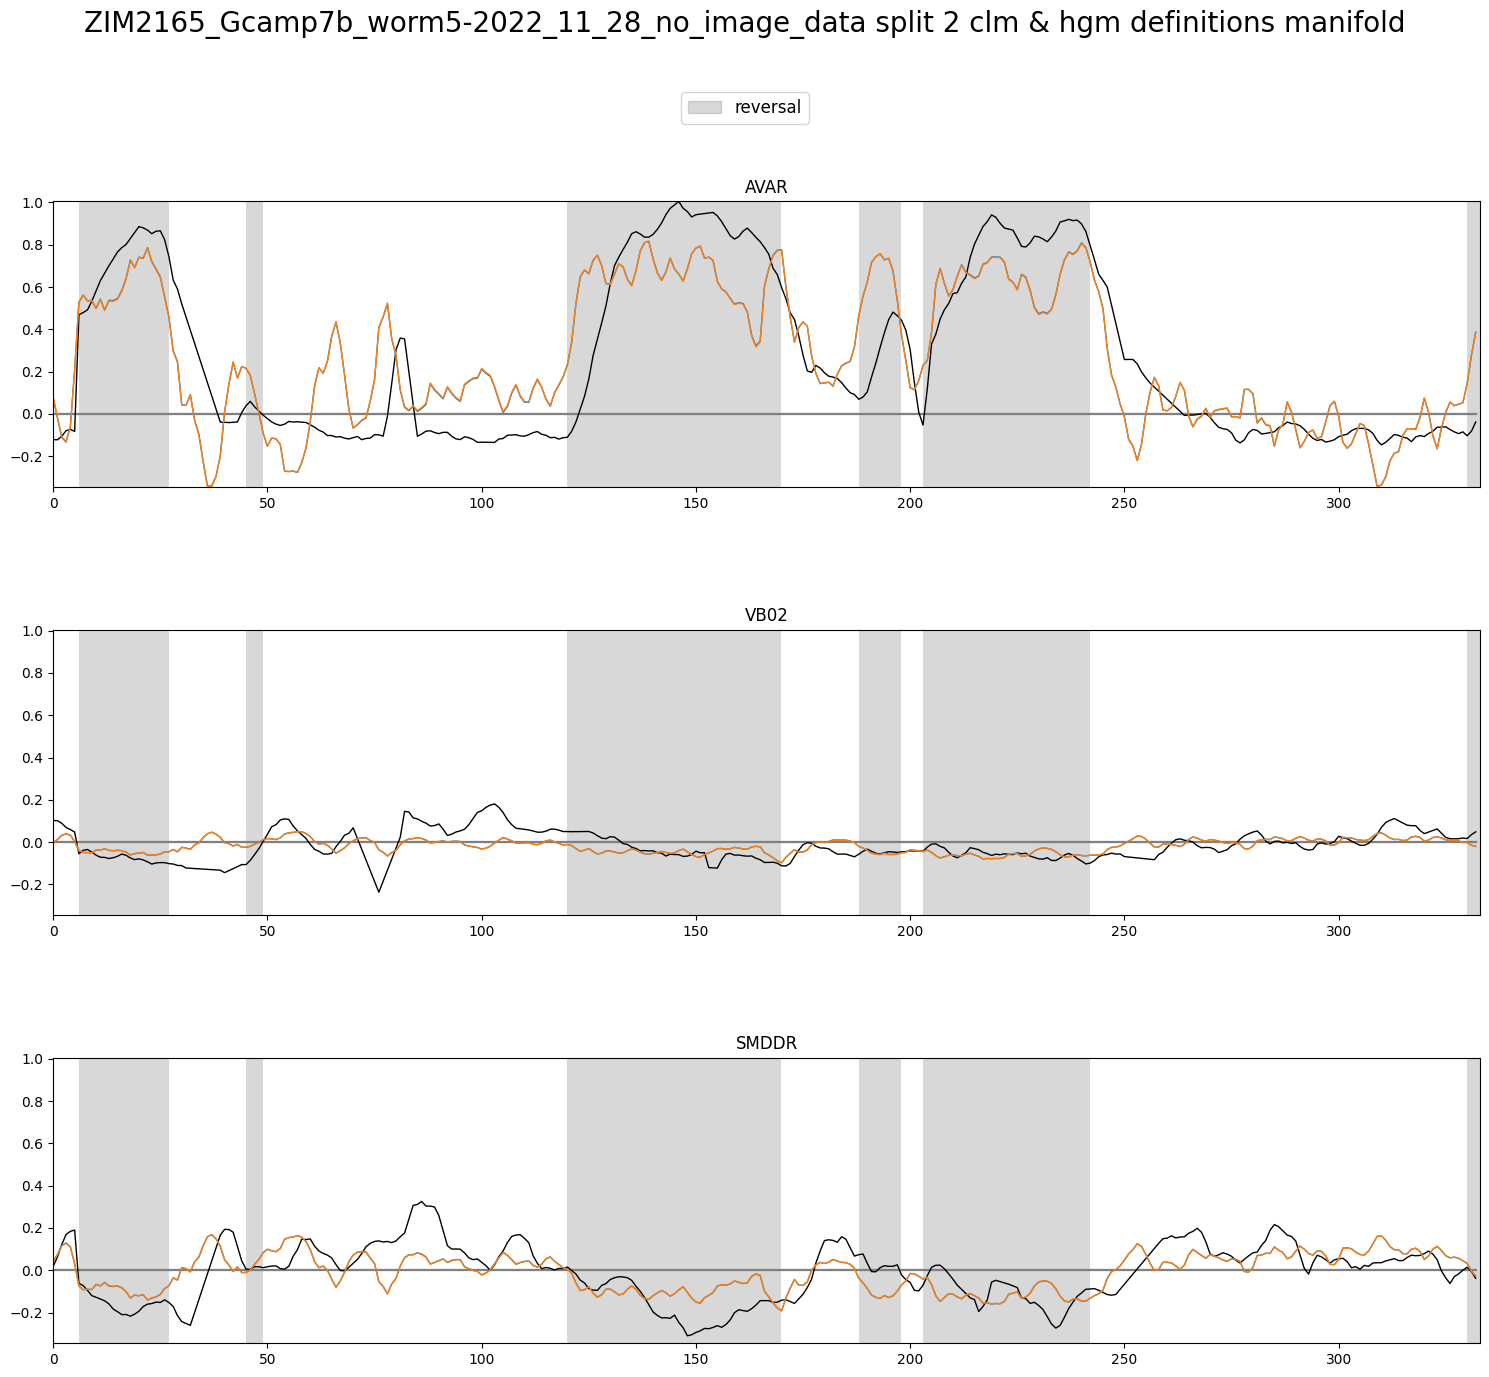

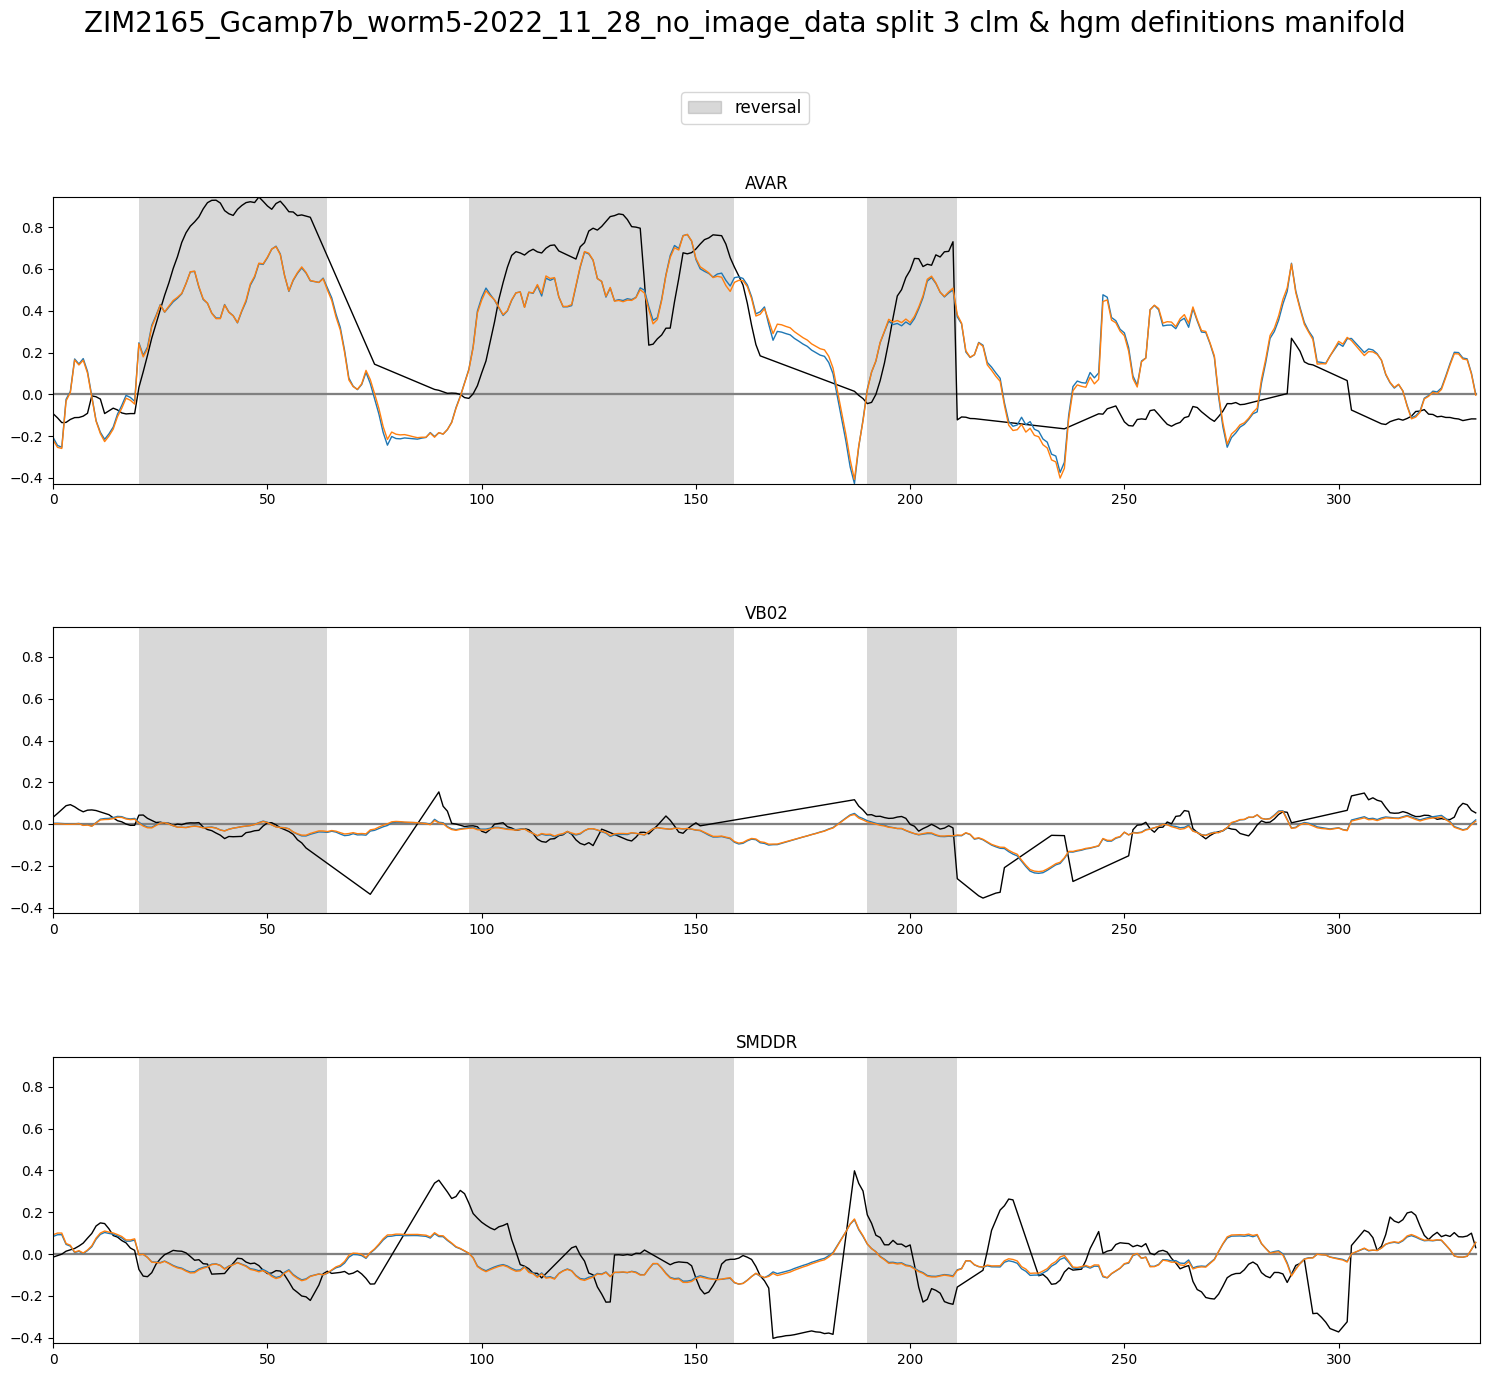

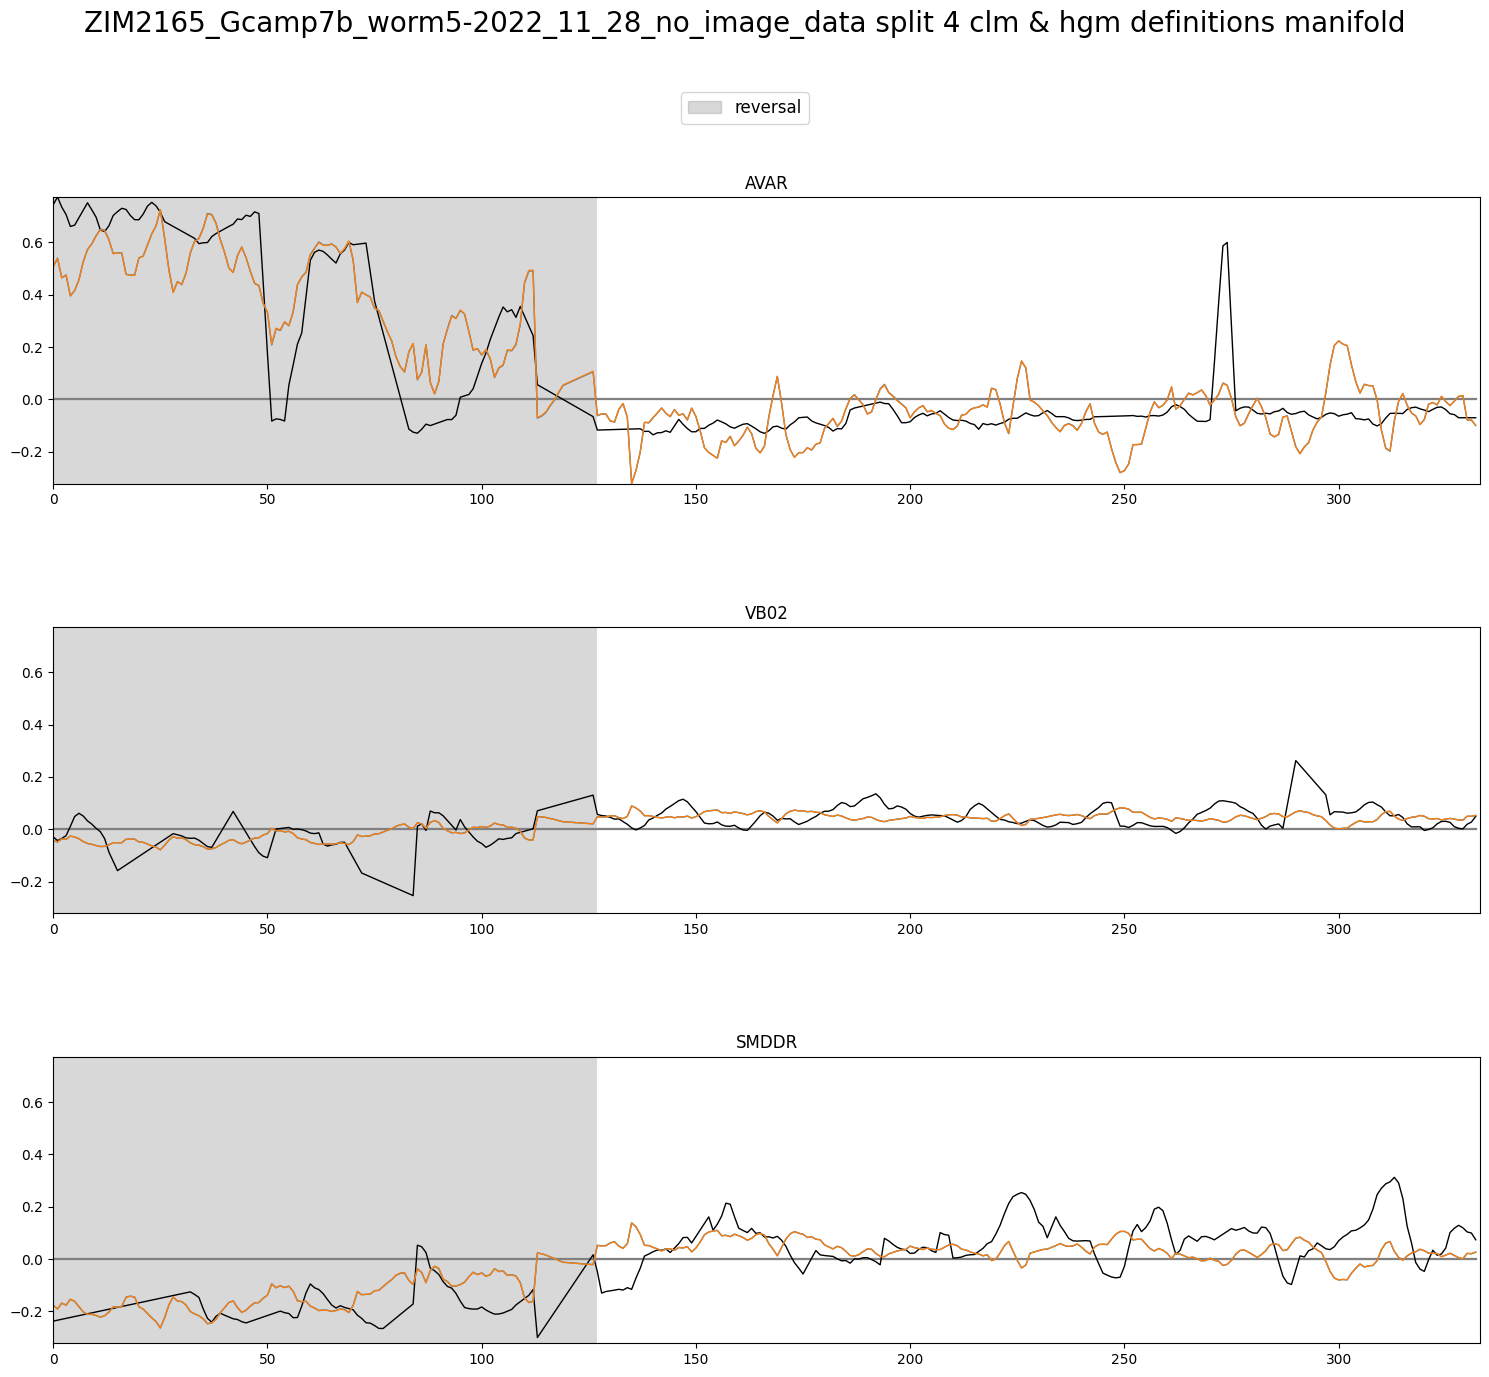

In [40]:
for i in range(5):
	plot_utils.plot_traces(f'{filenames[plot_id]} split {i} clm & hgm definitions manifold',
						   discrete_states_splits[plot_id][i]['REV'],
						   [traces_splits[plot_id][i][selection_n],
							clm_pres_res_rec[plot_id][i][2][selection_n], hgm_pres_res_rec[plot_id][i][2][selection_n]],
						   n_plots=len(selection_n), plots_per_row=1, ylimits=None)

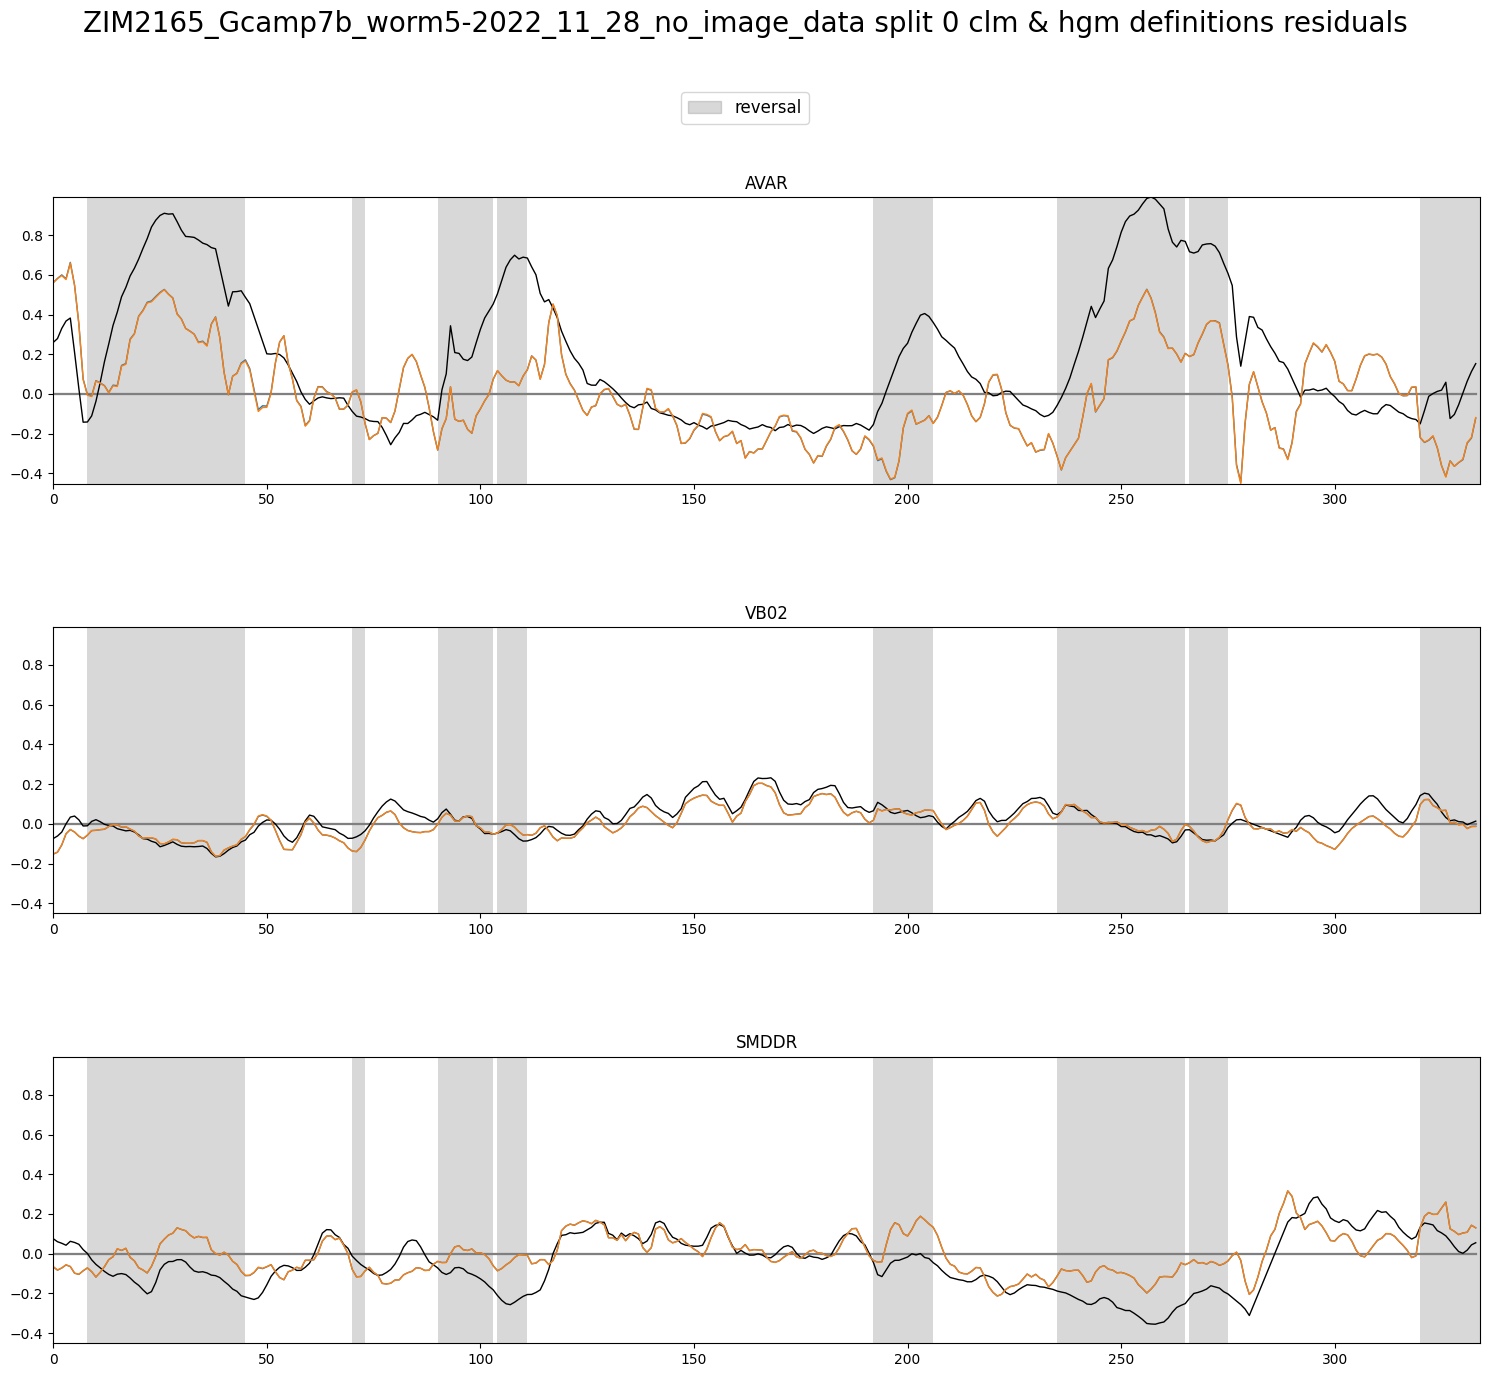

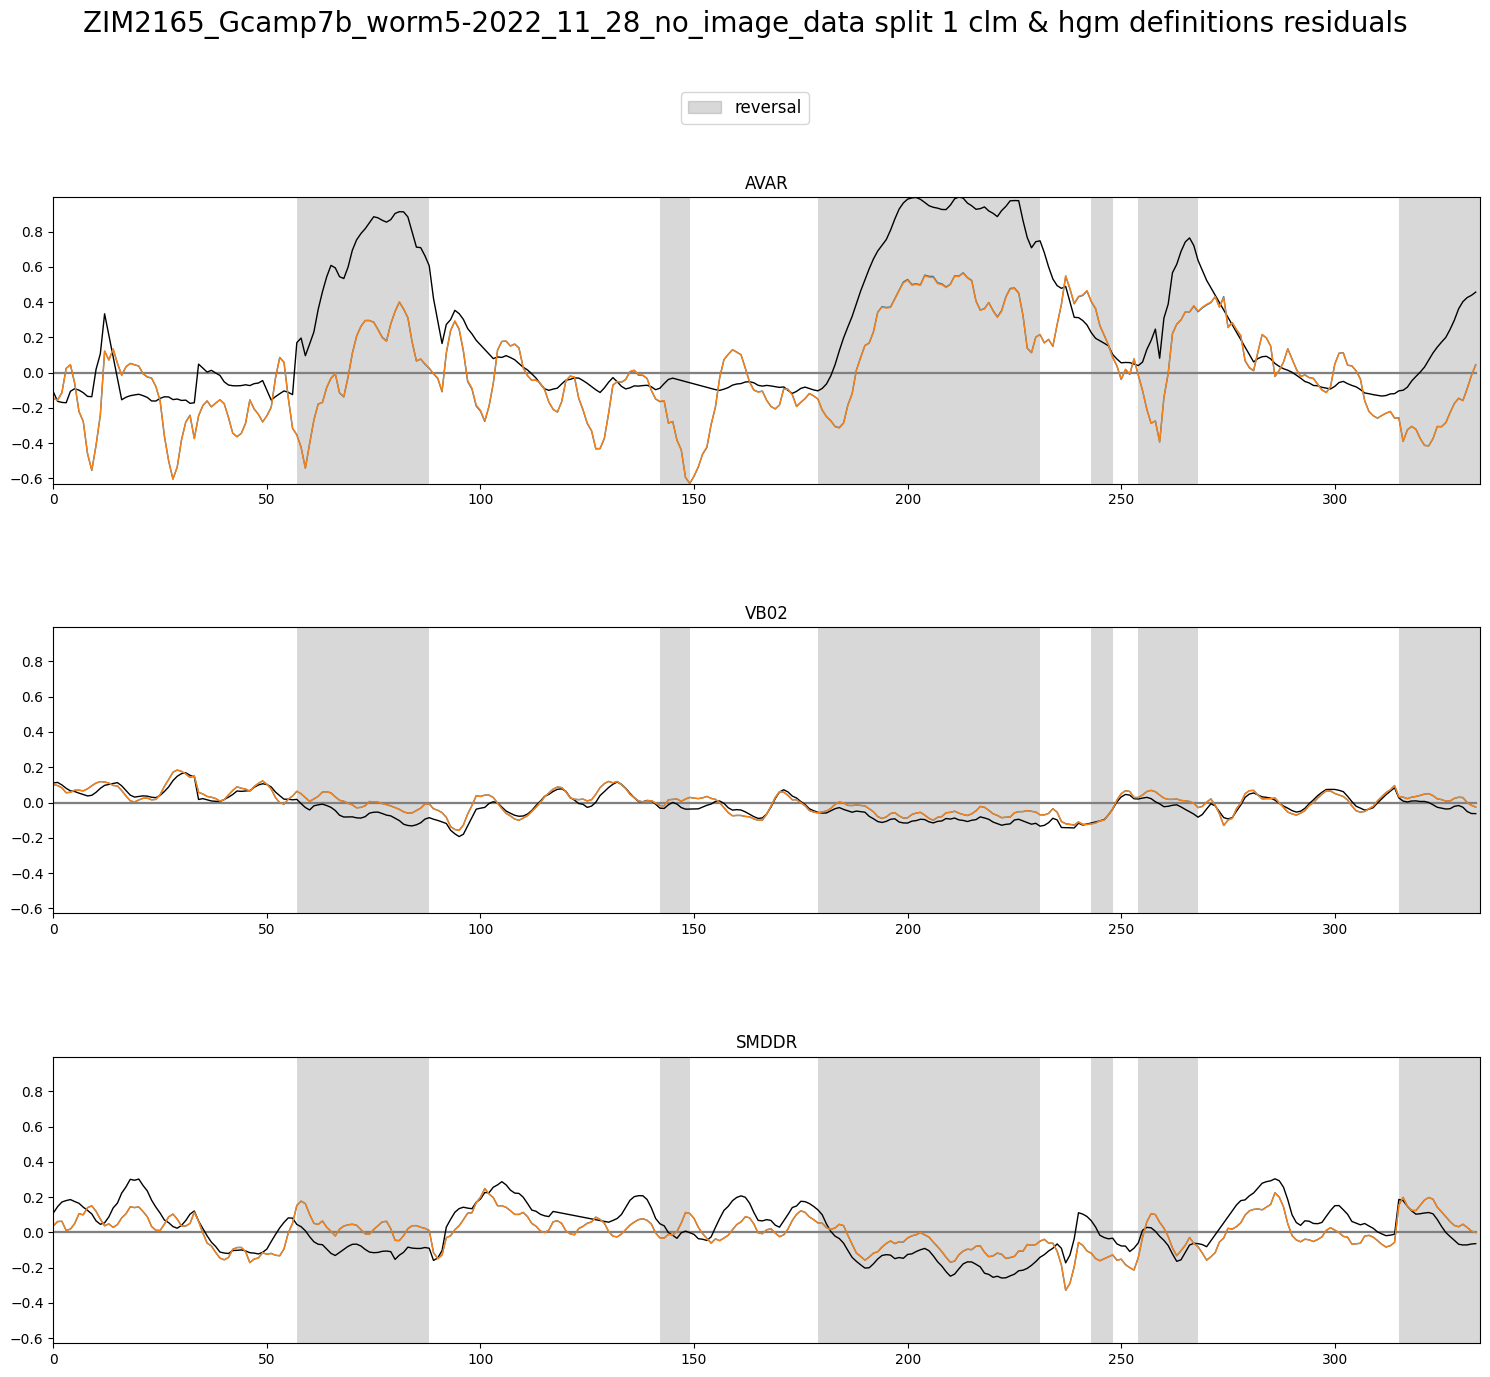

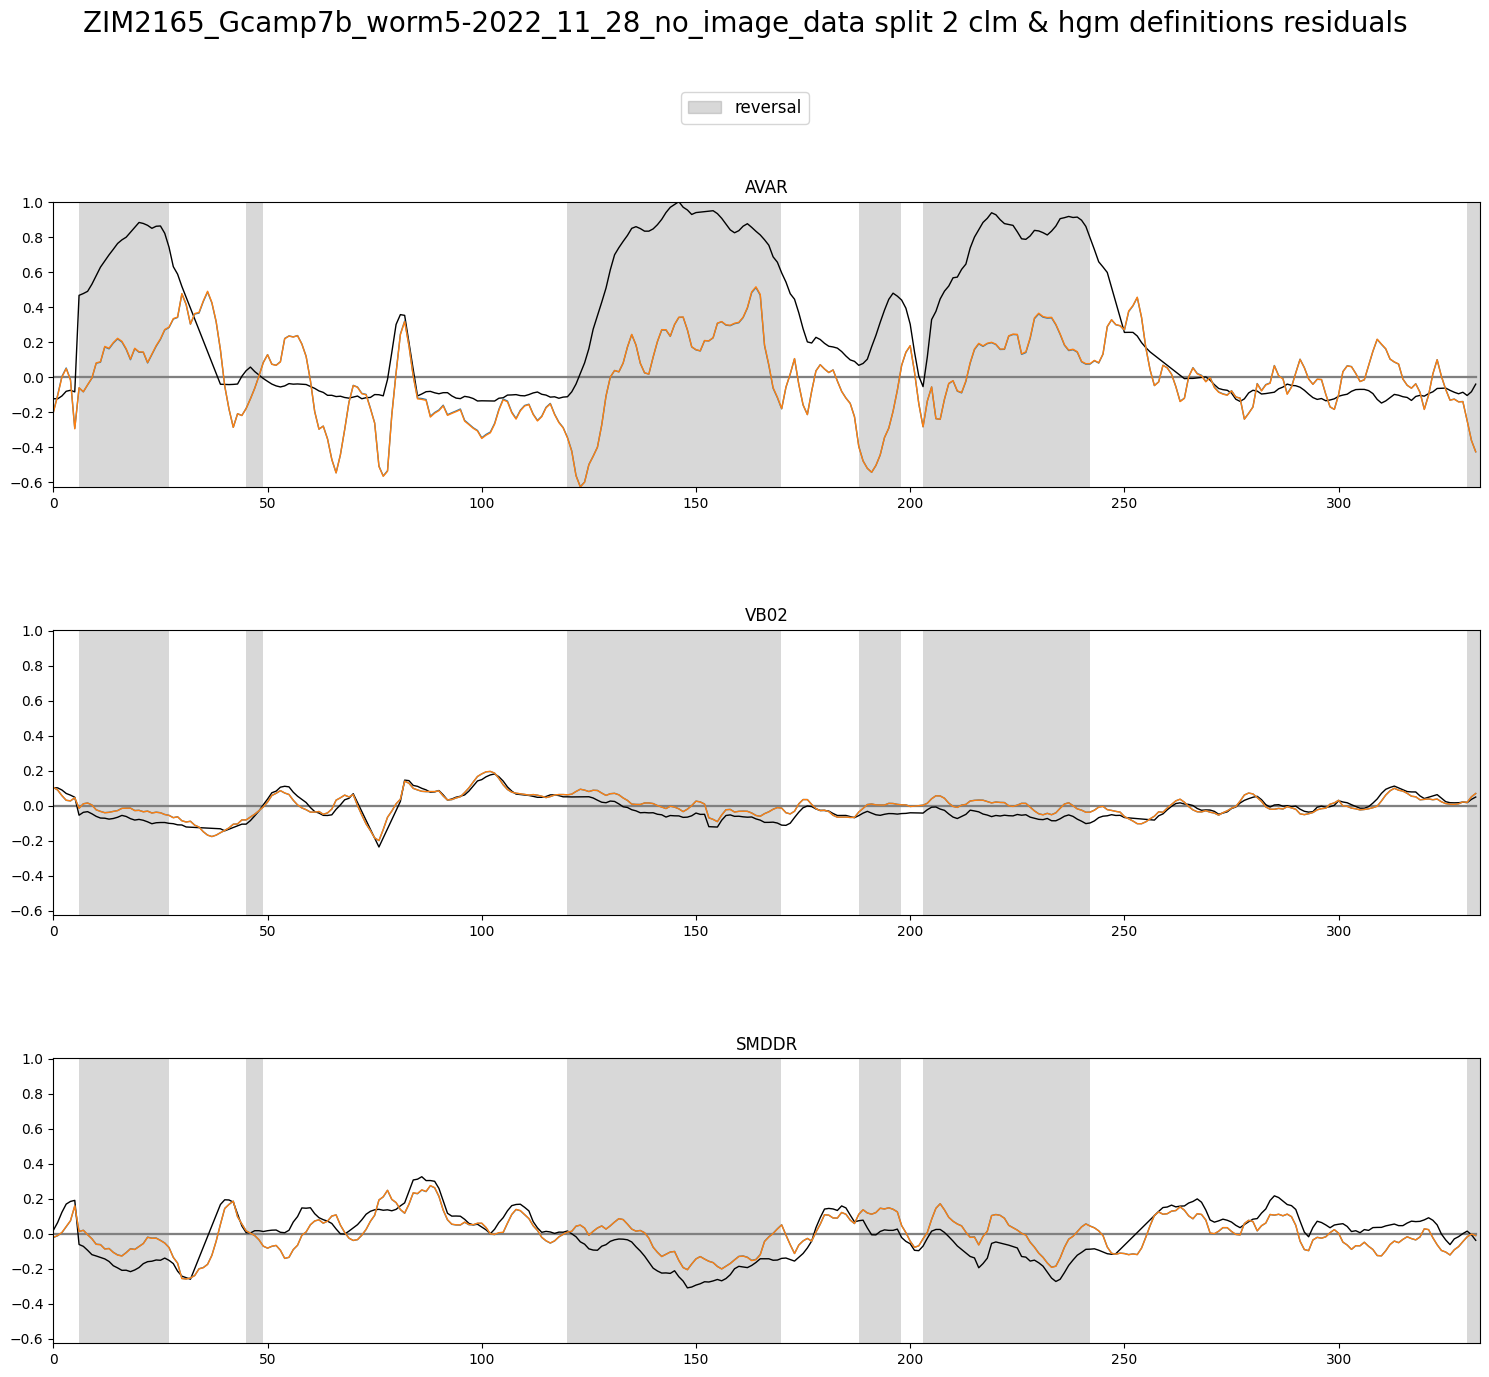

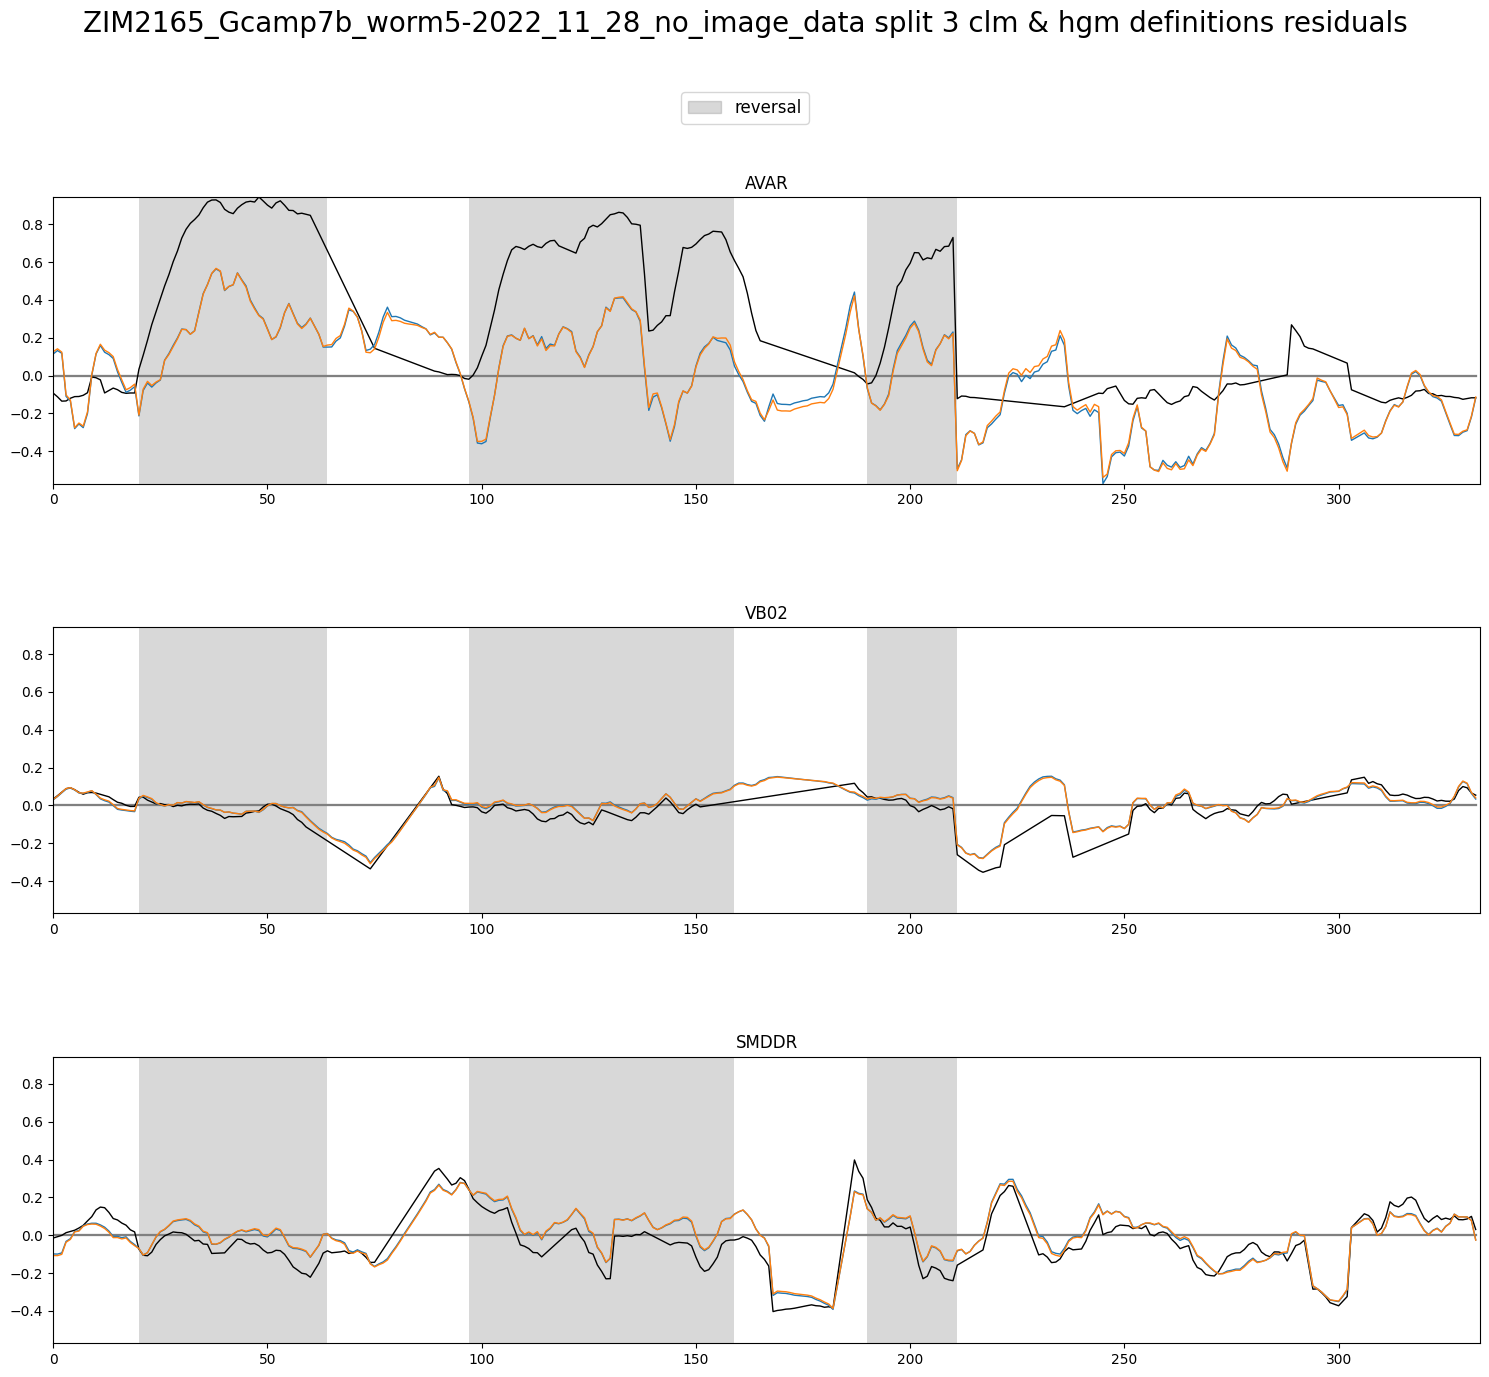

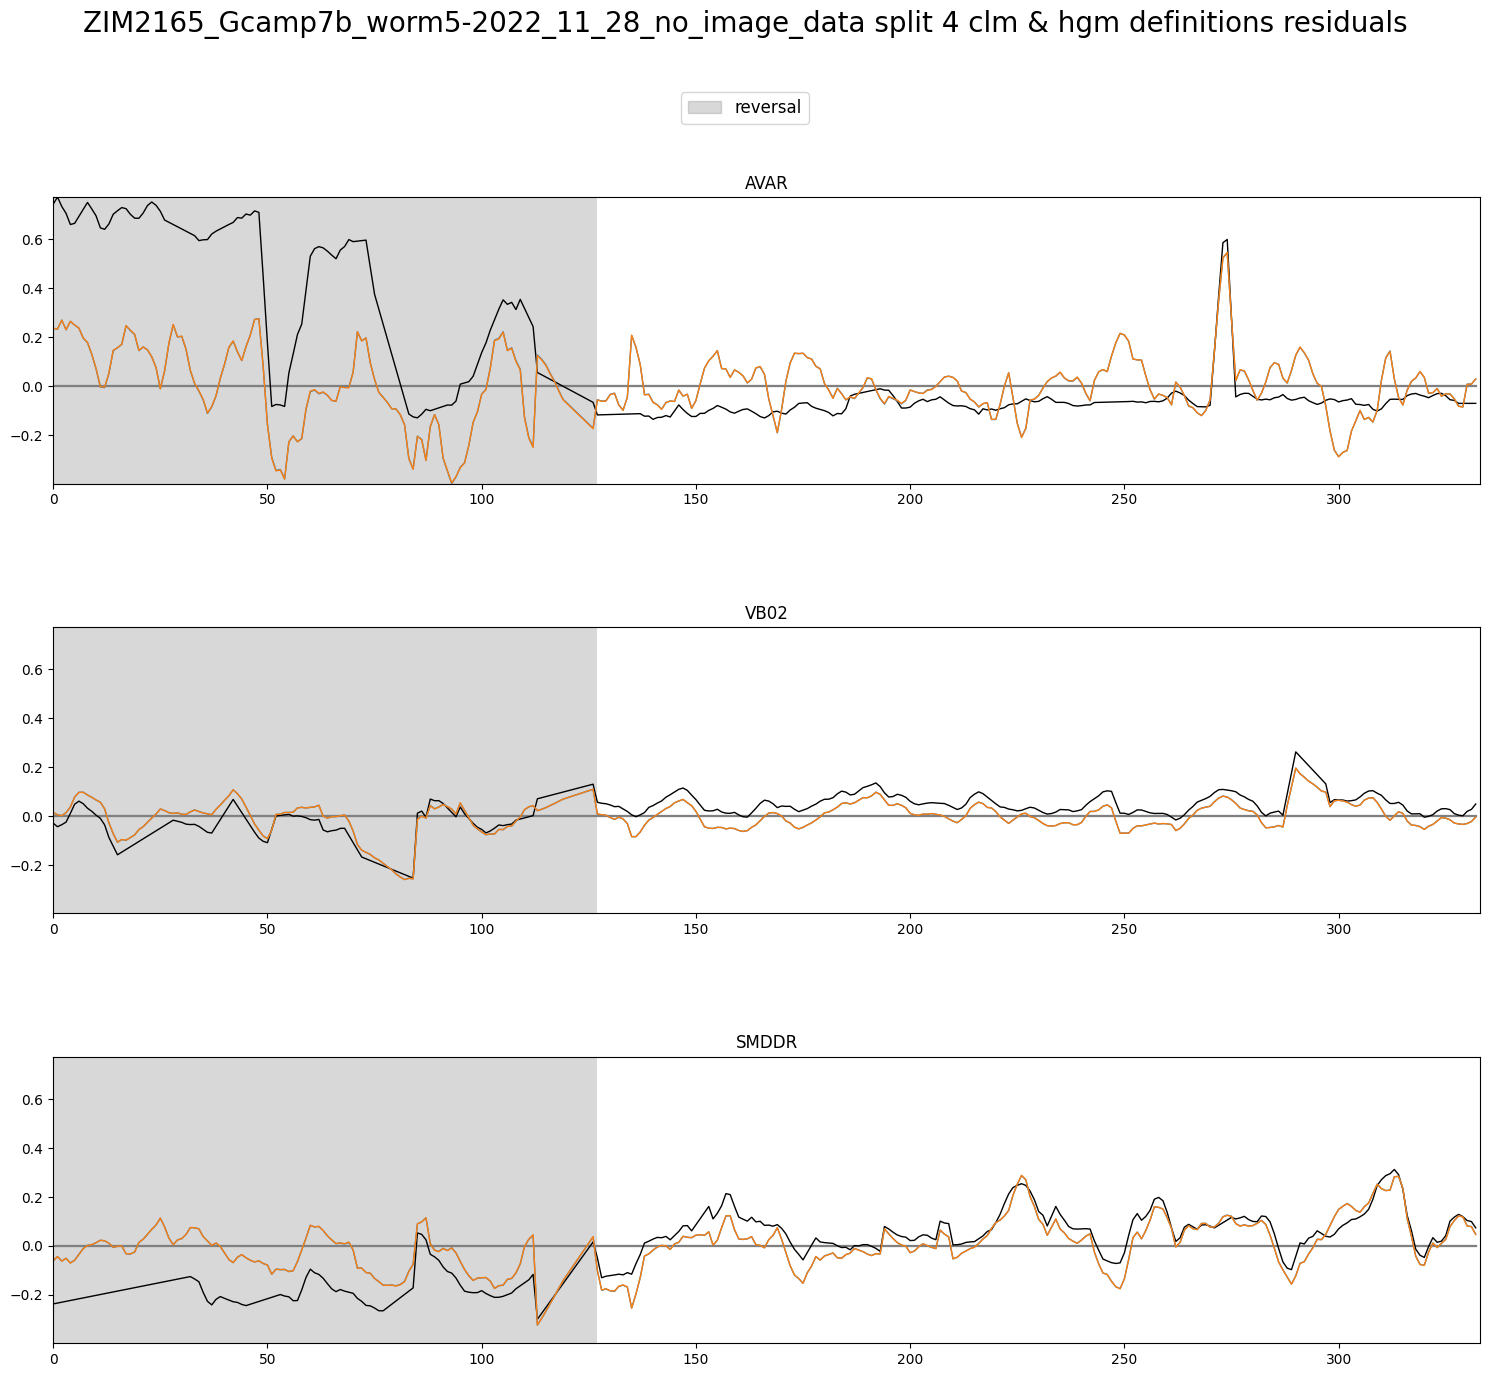

In [41]:
for i in range(5):
	plot_utils.plot_traces(f'{filenames[plot_id]} split {i} clm & hgm definitions residuals',
						   discrete_states_splits[plot_id][i]['REV'],
						   [traces_splits[plot_id][i][selection_n],
							clm_pres_res_rec[plot_id][i][1][selection_n], hgm_pres_res_rec[plot_id][i][1][selection_n]],
						   n_plots=len(selection_n), plots_per_row=1, ylimits=None)

In [42]:
# for i in range(5):
# 	plot_utils.plot_traces(f'{filenames[plot_id]} split {i} clm & hgm predictions residuals',
# 						   discrete_states_splits[plot_id][i]['REV'],
# 						   [traces_splits[plot_id][i][selection_n],
# 							clm_pres_res_rec[plot_id][i][0][selection_n], hgm_pres_res_rec[plot_id][i][0][selection_n]],
# 						   n_plots=len(selection_n), plots_per_row=1, ylimits=None)

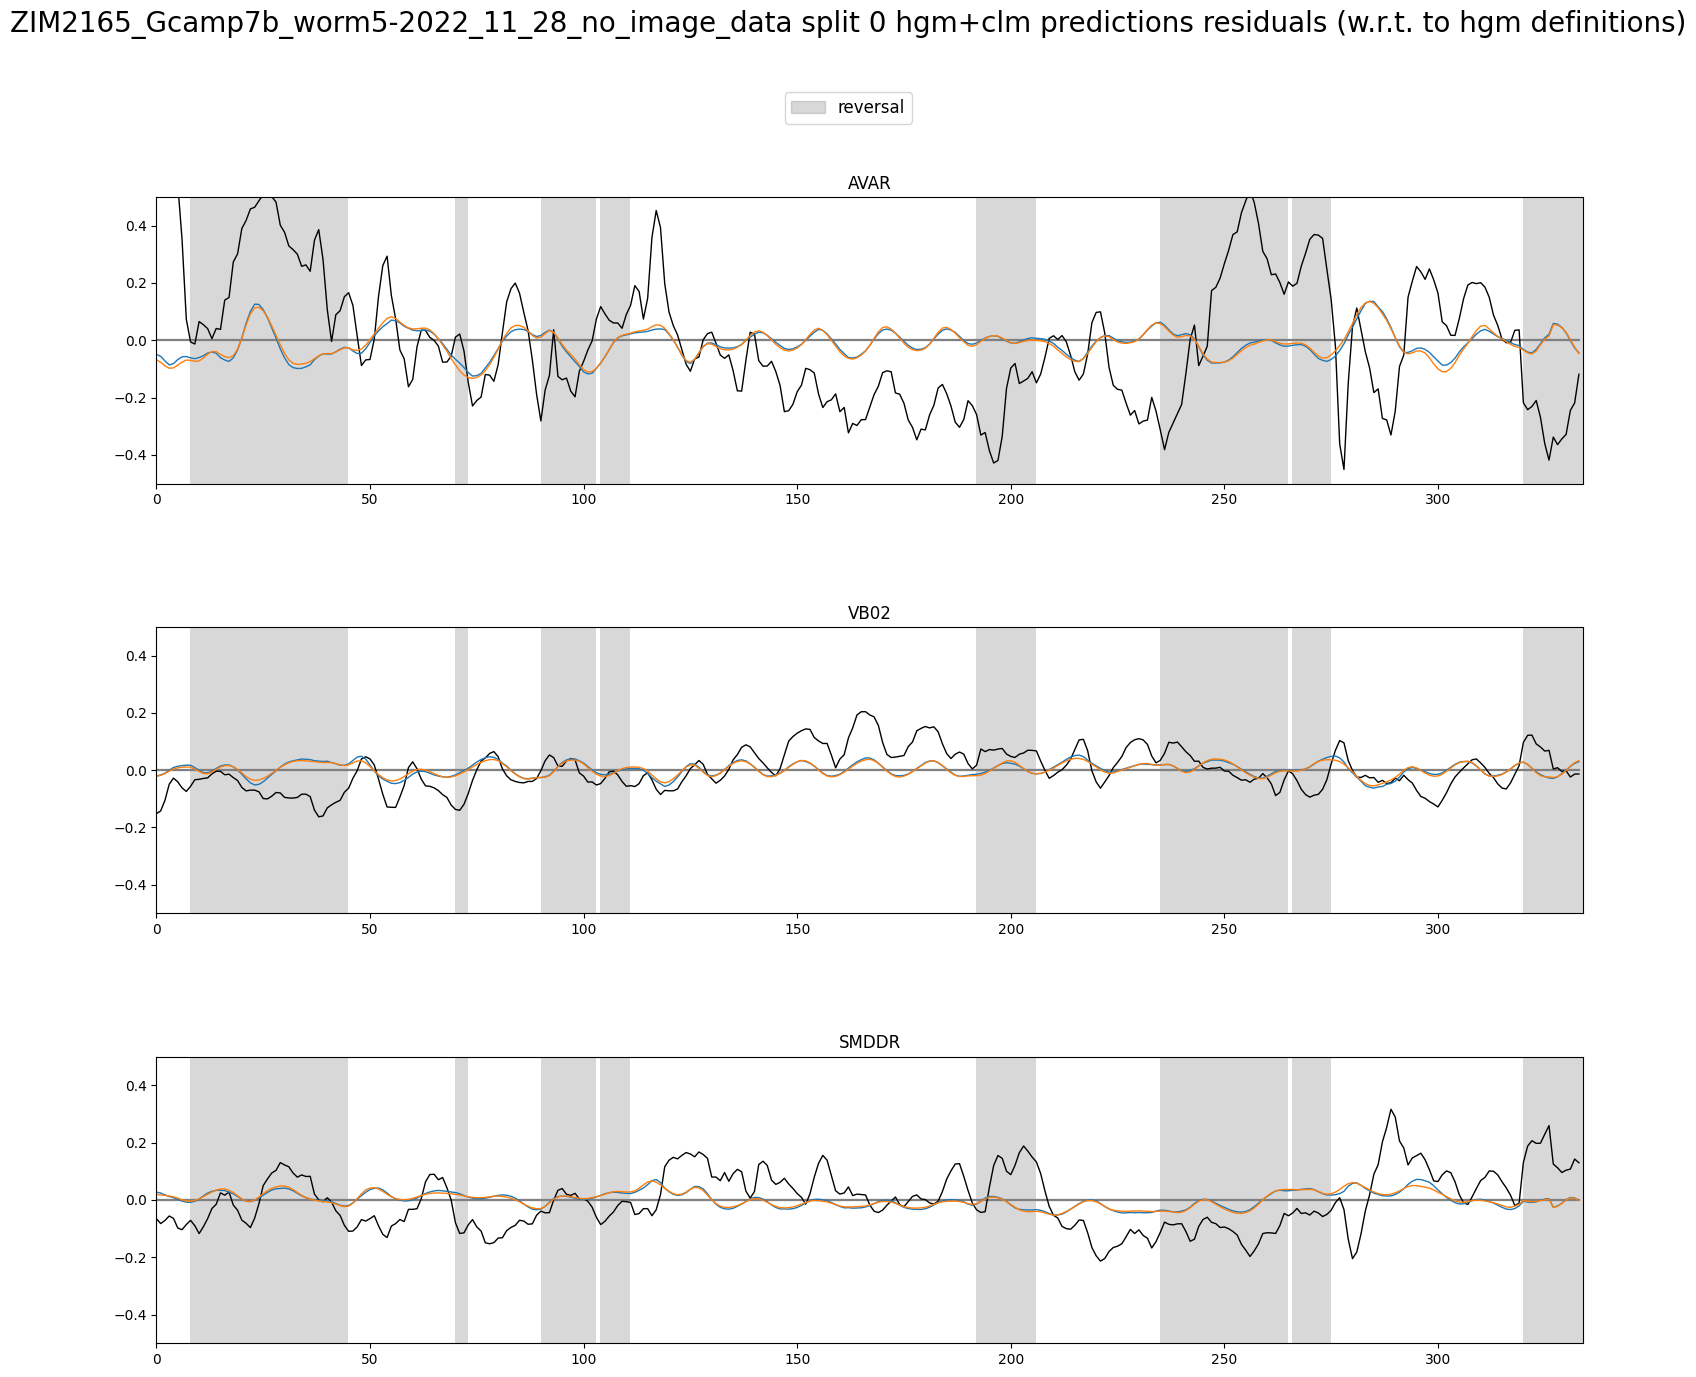

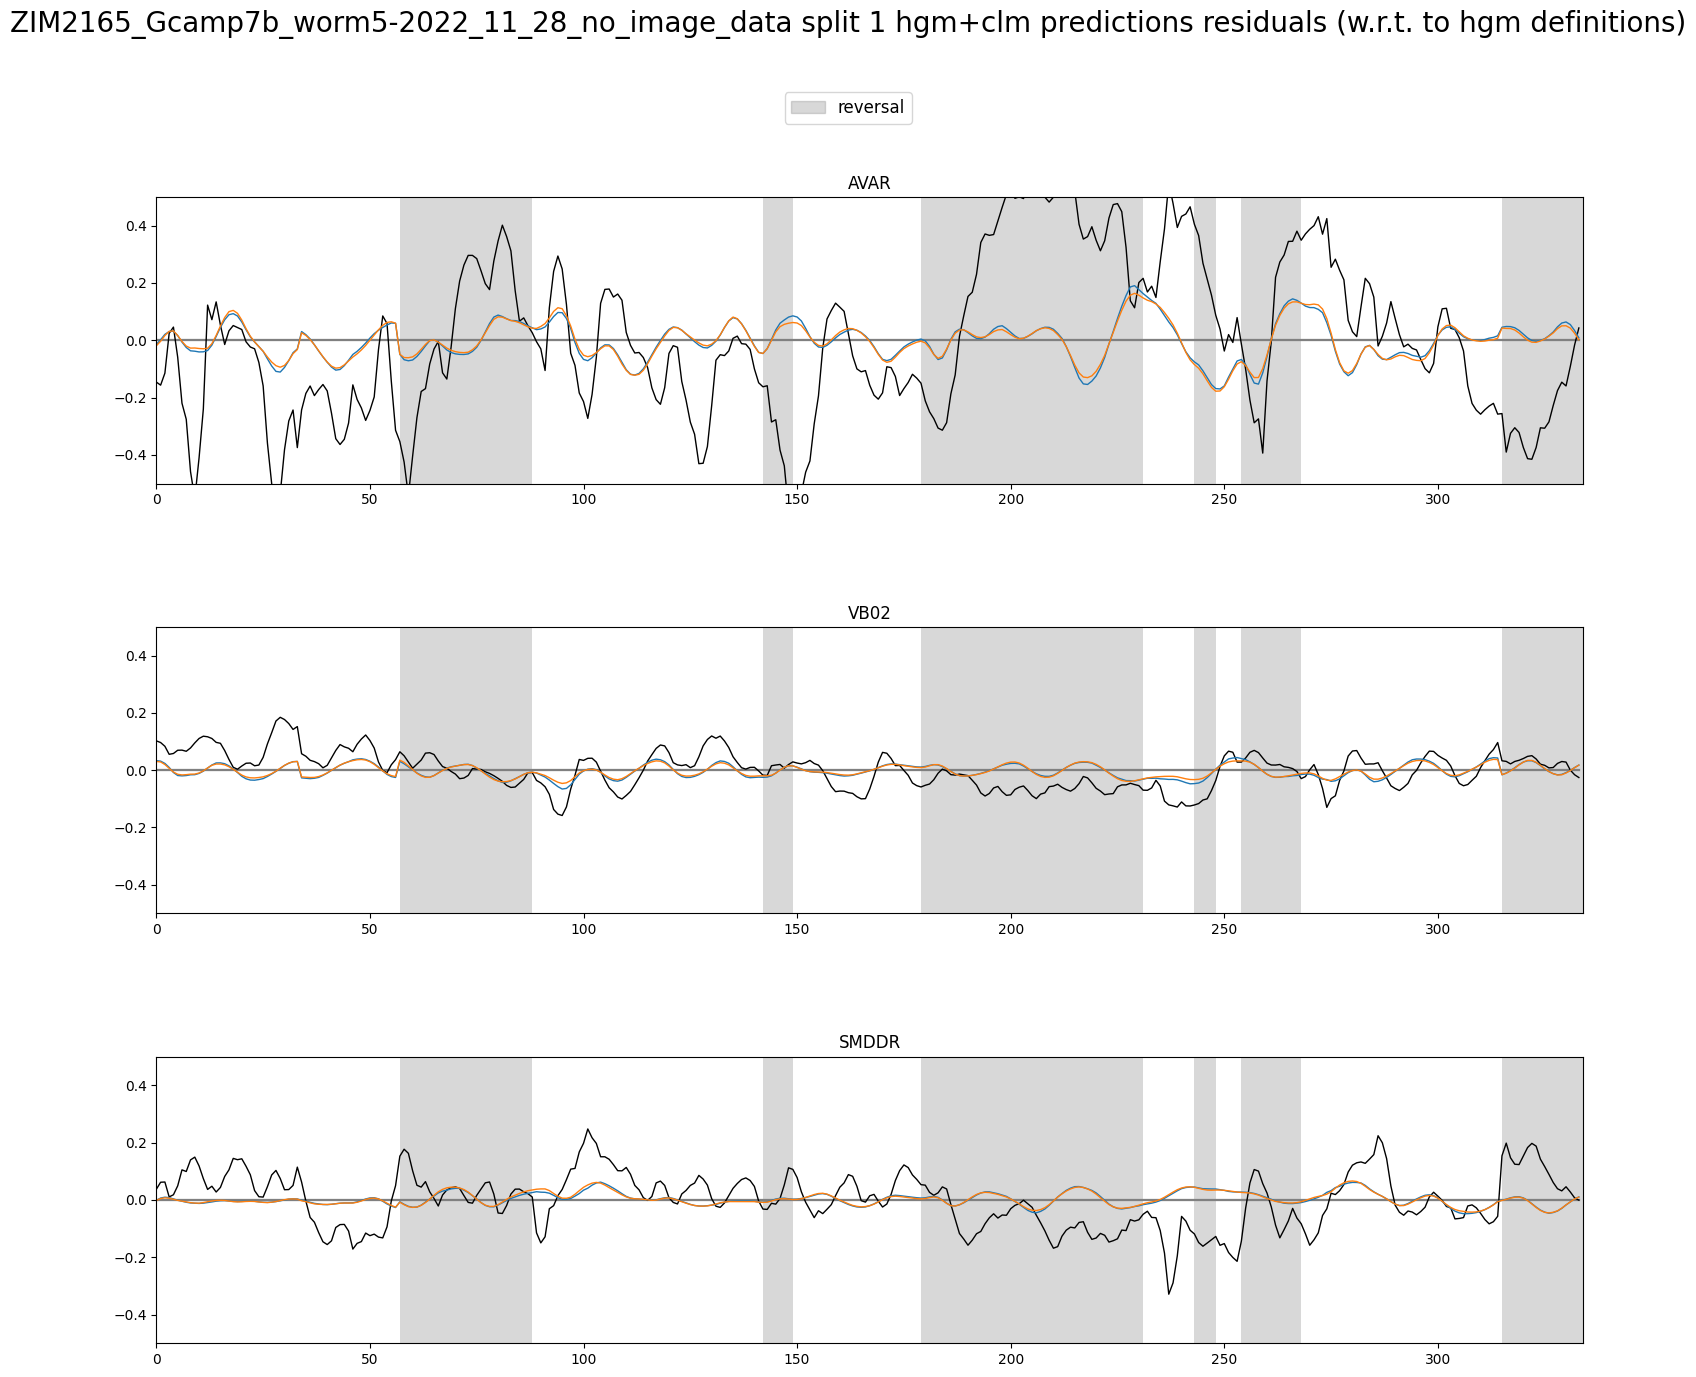

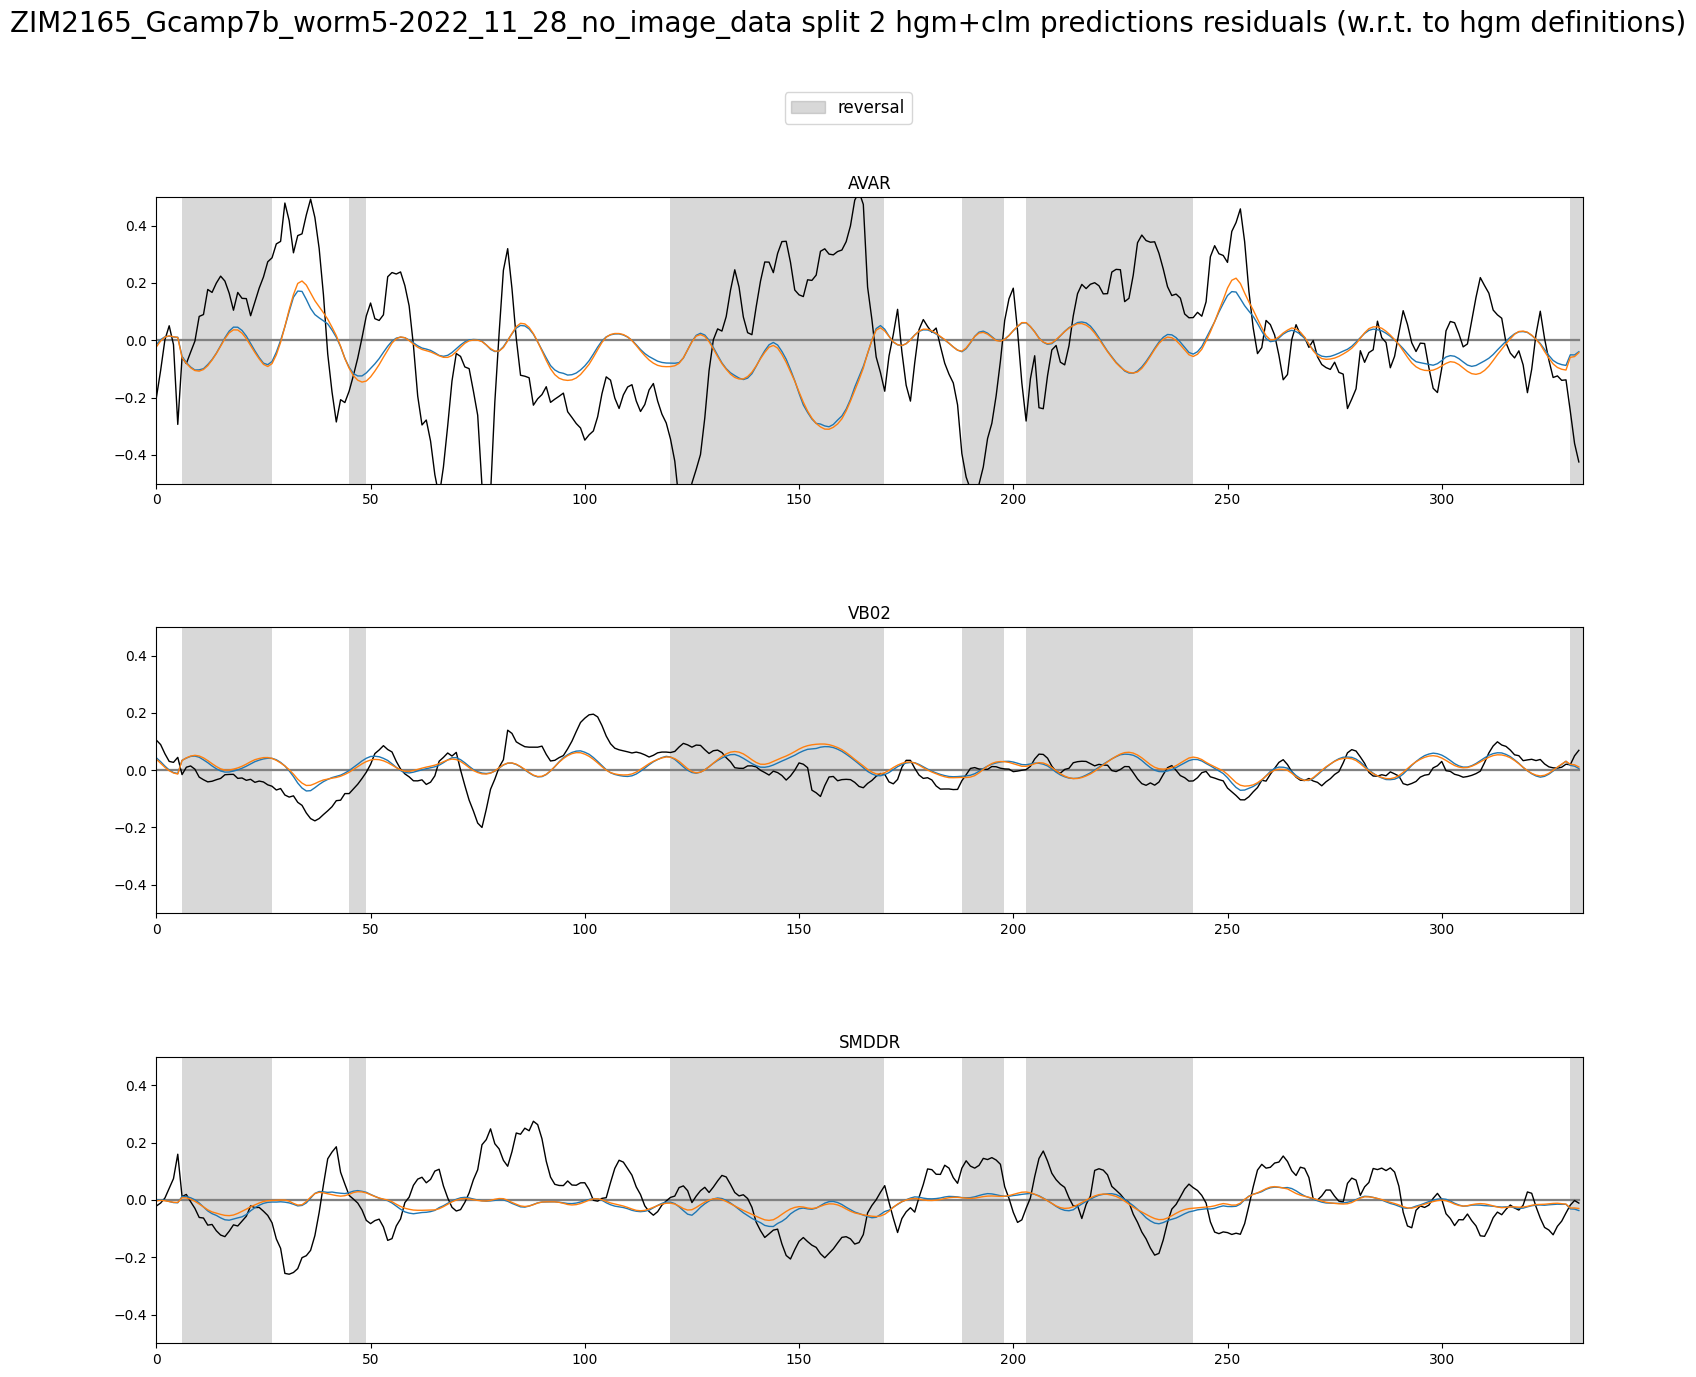

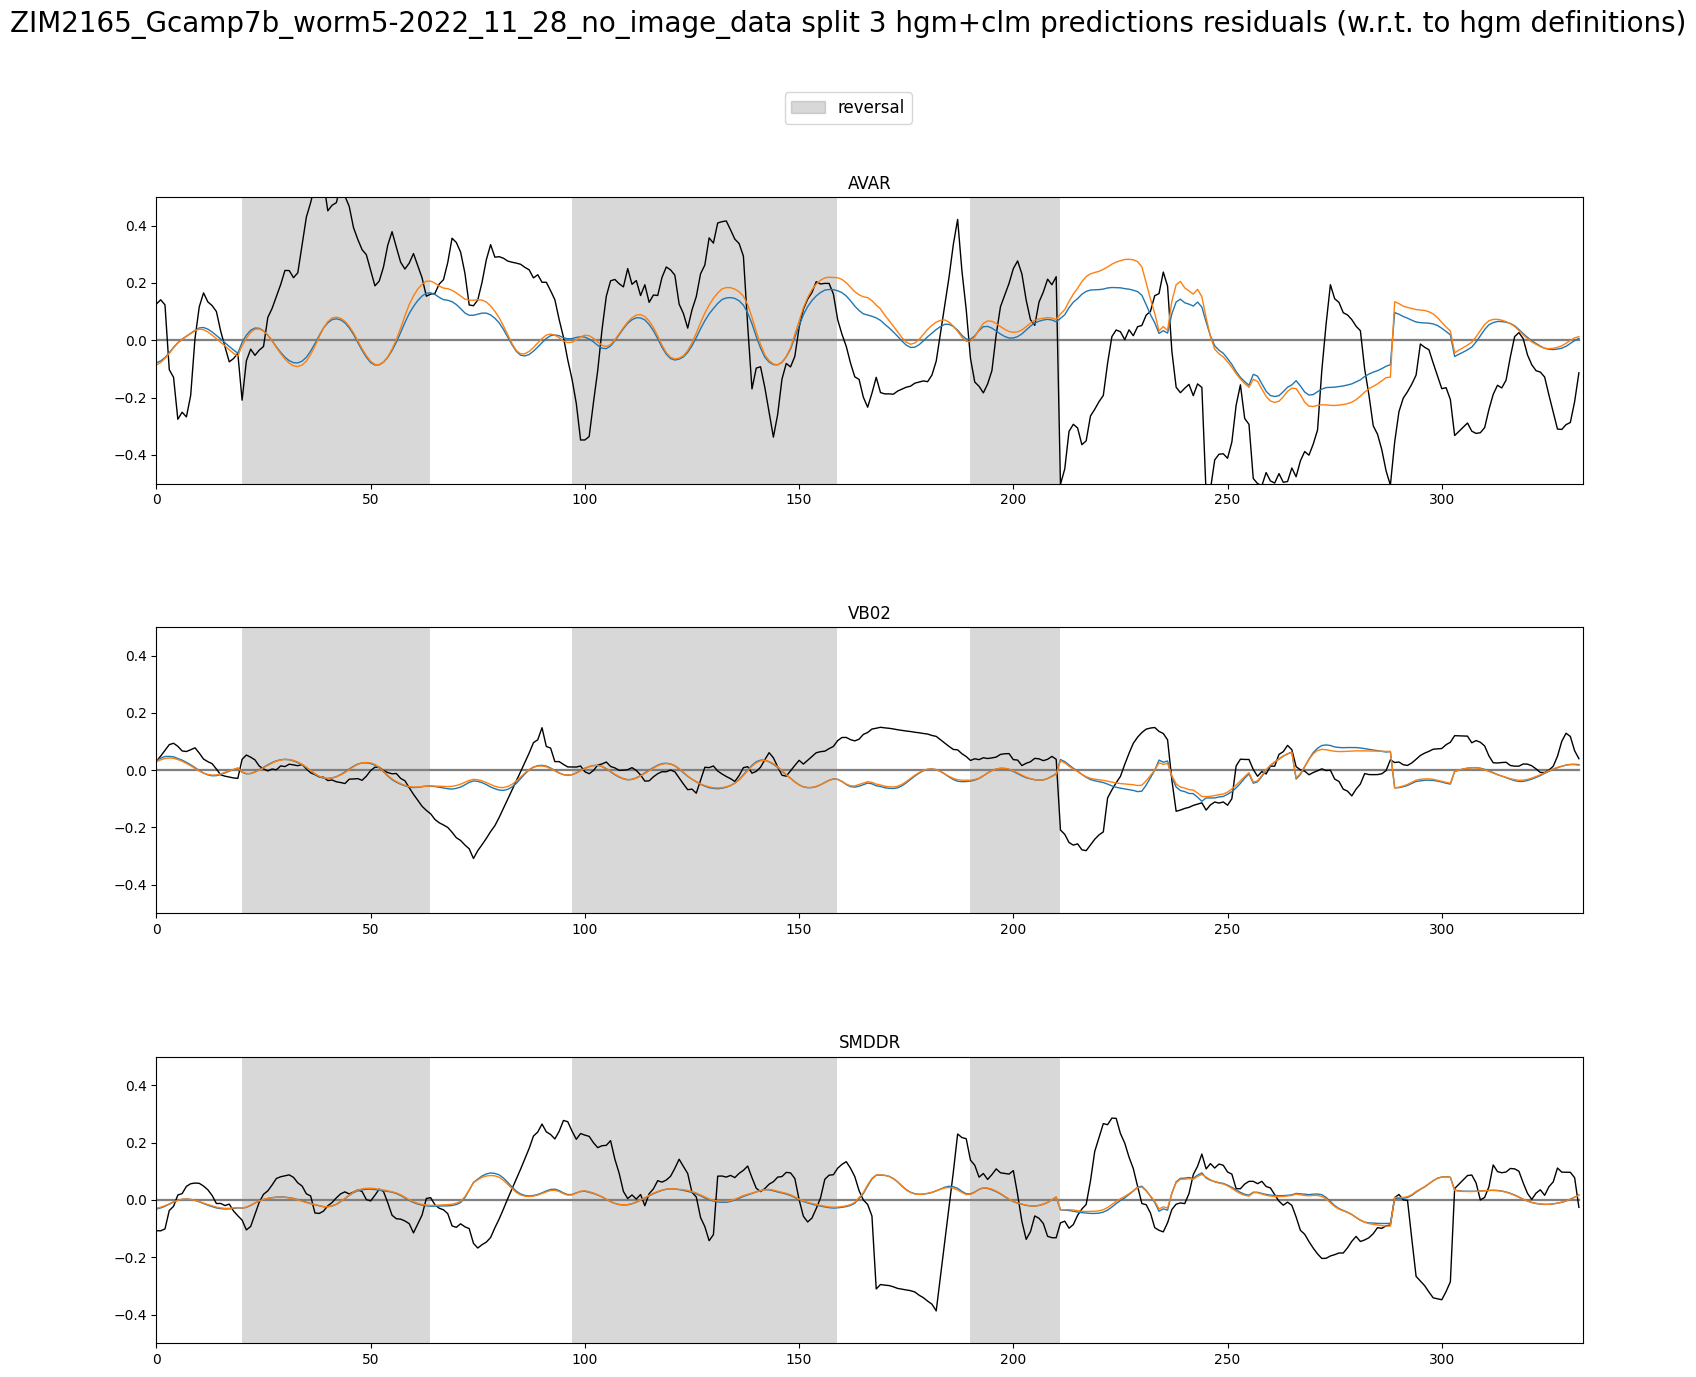

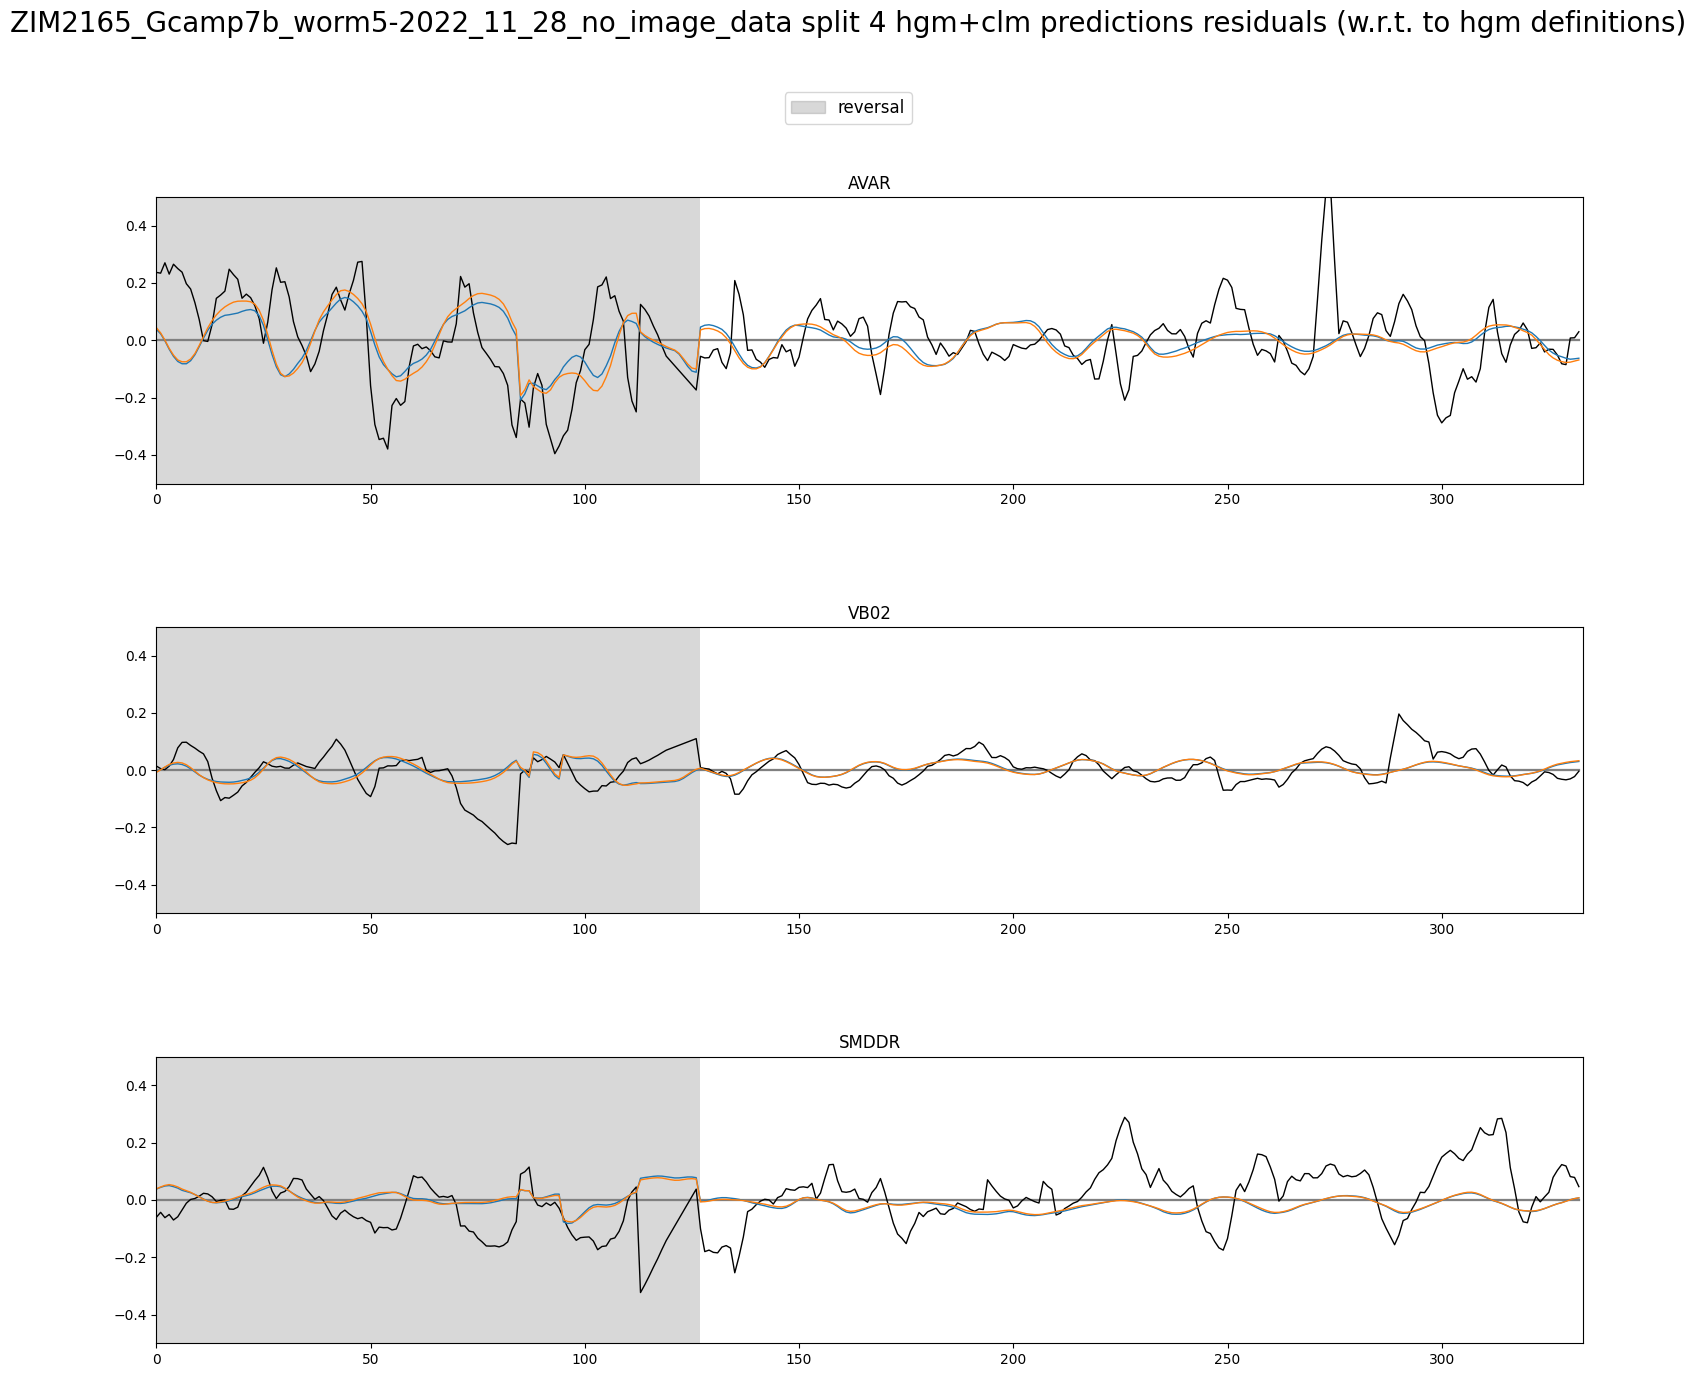

In [43]:
for i in range(5):
	plot_utils.plot_traces(f'{filenames[plot_id]} split {i} hgm+clm predictions residuals (w.r.t. to hgm definitions)',
						   discrete_states_splits[plot_id][i]['REV'],
						   [hgm_pres_res_rec[plot_id][i][1][selection_n],
							hgm_pres_res_rec[plot_id][i][0][selection_n], clm_pres_res_rec[plot_id][i][0][selection_n]],
						   n_plots=len(selection_n), plots_per_row=1, ylimits=(-0.5, 0.5))

In [44]:
# best improvements
neuron_diffs = {key: np.mean(neuron_scores[key][1] - neuron_scores[key][0]) for key in neuron_scores.keys()}
selection_n = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces[plot_id].columns][:10]

# best hgm scores
# neuron_hgmss = {key: np.mean(neuron_scores[key][1]) for key in neuron_scores.keys()}
# selection_n = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces[plot_id].columns][:10]